# Reingresos hospitalarios en cardiología: Risk Score Card

**Toda la parte de Python del caso, corregida y explicada paso a paso.**

**Datos:** base de datos MySQL `dm_cardiologia`, con 15.038 admisiones de 11.796 pacientes en el servicio de cardiología entre abril de 2022 y marzo de 2024. Son 5 tablas, todas con **una fila por admisión**: `admisiones`, `pacientes`, `factores_riesgo`, `pruebas_laboratorio` y `diagnosticos`.

## La idea del proyecto

Un **reingreso** es que un paciente que ya recibió el alta vuelva a ingresar. Los reingresos son caros para el hospital y suelen indicar que el paciente se fue a casa antes de tiempo o sin el seguimiento adecuado.

El objetivo es construir un **Risk Score Card (RSC)**: una tabla de puntos que, en el momento del alta, asigne a cada paciente una nota de **0 a 10** según su riesgo de reingresar. Así el equipo médico puede reforzar el seguimiento de los pacientes con nota alta.

El método es el clásico de *scorecard*, sencillo y explicable:

1. Se elige qué variables están más relacionadas con el reingreso (pruebas estadísticas).
2. Se convierten todas en categorías (las continuas, por tramos).
3. Se calcula la **penetración**: el % de reingresos en cada categoría. Esa penetración son los **puntos**.
4. La nota de un paciente es la suma de los puntos de sus categorías, reescalada de 0 a 10.

## Qué reúne este notebook

| Notebook original | Dónde está ahora |
|---|---|
| `01_Carga_e_integracion_de_datos.ipynb` | Pasos 1 y 2: conexión, carga e integración |
| `02_Calidad_y_EDA.ipynb` | Pasos 3 y 4: calidad del dato y EDA |
| `03_Minicubo_y_RSC.ipynb` | Pasos 5 a 9: variable objetivo, selección de variables, minicubo, scorecard y validación |
| `Produccion.ipynb` | Paso 10: script de producción |

Se conserva todo el análisis original. Donde había un error se explica qué fallaba y cómo se corrige (**Corrección**). Lo que se añade aparece como **Mejora**.

## Errores encontrados y corregidos

| # | Dónde | Qué fallaba | Consecuencia | Corrección |
|---|---|---|---|---|
| 1 | 01 y Producción | **La contraseña de MySQL está escrita en el código**, dos veces en 01 | Cualquiera que vea el notebook (GitHub, portfolio) tiene la contraseña | Se pide con `getpass` o se lee de una variable de entorno. **Cambia esa contraseña en MySQL si los notebooks se han publicado** |
| 2 | 01, 02 y 03 | Rutas absolutas a tu Escritorio (`C:/Users/<tu usuario>/Desktop/df.pickle`) | No funciona en otro ordenador y muestra tu usuario | Todo en un notebook; si hace falta caché, ruta relativa |
| 3 | 02 | No se detectaron los **1.238 episodios duplicados** (mismo paciente con las mismas fechas de ingreso y alta: 1.271 filas sobrantes) | Cada copia cuenta como un "reingreso" del mismo día. La tasa de reingreso del modelo sube del 14,8 % al 23,1 % | Se deja un registro por episodio |
| 4 | 02 | No se comprobaron otras incoherencias (contadas ya sin duplicados): 24 pacientes con dos géneros, 2 fallecidos que vuelven a ingresar, 90 ingresos que empiezan antes del alta anterior, 2.179 admisiones con ICFEr e ICFEn a la vez | Datos clínicamente imposibles que entran en el modelo sin avisar | Se documentan y se tratan |
| 5 | 03 | El reingreso es **cualquier ingreso posterior**, aunque sea 2 años después, y no se controla que los últimos ingresos no tienen "futuro" observable | Mezcla reingresos evitables con ingresos nuevos sin relación. Los ingresos de los últimos meses parecen "sin reingreso" porque no ha dado tiempo | Se usa el indicador estándar, **reingreso a 30 días**, y se excluyen las altas sin 30 días de seguimiento. La ventana es un parámetro: con `None` se recupera la definición original |
| 6 | 03 | **El scoring nunca suma los puntos de edad ni de las estancias.** La función pregunta `if "edad_disc" in registro`, pero esas columnas solo existen en `disc_df`, no en `risk` ni en Producción. Además, aunque existieran, son intervalos de `pd.cut`, no texto, y la comparación con `"(0, 10]"` nunca sería cierta | La nota se calcula solo con 9 de las 12 variables. Se ve en el rango que sale, 84-457, que es exactamente la suma de los mínimos y máximos de las 9 binarias | La función discretiza ella misma y busca los puntos en la tabla |
| 7 | 03 y Producción | Escala 0-10 con el mínimo y máximo **de los datos de esa ejecución** (el texto decía "el que se puede conseguir con nuestra tabla") | En producción, la nota de un paciente cambia según qué otros pacientes entren en la carga | Mínimo y máximo **teóricos** de la scorecard, fijos |
| 8 | 03 | `astype('int')` **trunca**: 8,88 pasa a 8 y 9,99 a 9 | Solo la puntuación máxima posible llega a 10 | Se redondea |
| 9 | 03 | "Las 3 continuas más significativas" se tomaban con `significativas_con[:3]`, que son las 3 primeras **por orden de columna** | Se eligieron edad y estancias sin comprobar que fueran las mejores | Se ordenan por p-valor |
| 10 | 03 | Las variables se eligen y los puntos se calculan con **todos** los datos, y con esos mismos datos se comprueba que funciona | No hay forma de saber si el modelo funciona con pacientes nuevos | Se separa un periodo de **prueba** (desde julio de 2023) y se mide el AUC |
| 11 | 03 | El ranking de chi-cuadrado incluía la propia variable objetivo (por eso se empezaba en `[1:10]`) | Funciona, pero es frágil | Se excluye explícitamente |
| 12 | 03 | `insuficiencia_cardiaca`, `icfer` e `icfen` puntúan por separado, y clínicamente son la misma enfermedad y sus dos tipos | En datos reales, un paciente con IC sumaría puntos hasta 3 veces por lo mismo. En estos datos apenas están relacionadas (correlación 0,28) | Se comprueba y se explica |
| 13 | 03 | Celdas ejecutadas fuera de orden (contadores 43, 76, 77, 78, 79, 44...) | La tabla `rsc` guardada con la columna `puntos` es el minicubo ancho, no la tabla de puntos | Se ejecuta de arriba abajo; los puntos salen del minicubo |
| 14 | 03 y Producción | La función de scoring se escribió a mano (con la IA) copiando números | Si cambian los datos, hay que reescribirla; un número mal copiado no se detecta | La tabla de puntos se genera y se guarda en un archivo que Producción lee |
| 15 | Producción | No eliminaba duplicados y ordenaba sin desempatar | Mismo problema que el error 3; con dos ingresos en la misma fecha el orden era aleatorio | Igual que en desarrollo |
| 16 | 01 | `con.connect()` abría una conexión nueva en cada lectura y no la cerraba | Conexiones abiertas de más | Un solo bloque `with engine.connect()` |
| 17 | Todos | `sys.executable` muestra la ruta de tu usuario de Windows | Dato personal en un portfolio | Se elimina |

## Cómo usar este notebook

1. Ten el servidor MySQL arrancado con la base `dm_cardiologia` cargada (con tu dump `BD_Cardiologia_Dump.sql`).
2. Ejecuta **Kernel → Restart & Run All**. Al llegar a la conexión te pedirá la contraseña de MySQL, que no queda guardada en ningún sitio.
3. Librerías: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn`, `sqlalchemy`, `pymysql`.

Este notebook se ha ejecutado contra **una copia SQLite generada a partir de tu dump**, con las mismas tablas y los mismos datos. El código es el mismo para MySQL y para SQLite: solo cambia la dirección de conexión (paso 1).

## 1. Preparación y conexión

**Corrección (error 1): la contraseña no se escribe en el código.** En el original aparecía dos veces en 01 (en la variable `contrasena` y otra vez dentro de la cadena de conexión) y otra en Producción. Un notebook se comparte, se sube a GitHub y se imprime: cualquier contraseña escrita en él deja de ser secreta.

La conexión se resuelve así:

- Si existe la variable de entorno `URL_BD_CARDIOLOGIA`, se usa. Es lo habitual en producción: el servidor tiene la dirección configurada y el código no la conoce.
- Si no existe, se monta la dirección de MySQL. La contraseña se toma de la variable de entorno `MYSQL_PASSWORD` y, si tampoco está definida, se pide con `getpass`, que la lee sin mostrarla en pantalla ni guardarla en el notebook.

`quote_plus` codifica caracteres especiales de la contraseña (`@`, `/`, `:`...), que si no romperían la dirección de conexión.

In [1]:
import os
from getpass import getpass
from pathlib import Path
from urllib.parse import quote_plus

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency, ttest_ind
from sklearn.metrics import roc_auc_score
from sqlalchemy import create_engine, inspect

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

URL_BD = os.environ.get('URL_BD_CARDIOLOGIA')
if URL_BD is None:
    usuario = 'root'
    host = 'localhost'
    puerto = 3306
    base_datos = 'dm_cardiologia'
    # La contraseña se lee de la variable de entorno MYSQL_PASSWORD; si no existe, se pide por pantalla
    contrasena = os.environ.get('MYSQL_PASSWORD') or getpass('Contraseña de MySQL: ')
    URL_BD = f'mysql+pymysql://{usuario}:{quote_plus(contrasena)}@{host}:{puerto}/{base_datos}'

engine = create_engine(URL_BD)
print('Conectado a:', engine.dialect.name)

Conectado a: mysql


`create_engine` no abre todavía ninguna conexión: crea el "motor", que las abrirá cuando haga falta.

Si no supiéramos qué tablas contiene la base de datos, podríamos verlo así:

In [2]:
inspector = inspect(engine)
print('Tablas en la base de datos:')
for tabla in inspector.get_table_names():
    print(' ', tabla)

Tablas en la base de datos:
  admisiones
  diagnosticos
  factores_riesgo
  pacientes
  pruebas_laboratorio


## 2. Carga e integración (`01_Carga_e_integracion`)

### 2.1 Carga

**Corrección (error 16):** el original hacía `pd.read_sql(..., con.connect())` en cada lectura, que abre una conexión nueva cada vez sin cerrarla. Con `with engine.connect() as conexion:` se abre **una** conexión para las 5 lecturas y se cierra sola al salir del bloque, aunque haya un error.

`parse_dates` convierte las fechas al leerlas. En MySQL ya llegan como fecha; en SQLite llegan como texto. Así el resultado es el mismo con las dos bases.

In [3]:
TABLAS = ['admisiones', 'diagnosticos', 'factores_riesgo', 'pacientes', 'pruebas_laboratorio']

with engine.connect() as conexion:
    admisiones = pd.read_sql('SELECT * FROM admisiones', conexion, parse_dates=['fecha_admision', 'fecha_alta'])
    diagnosticos = pd.read_sql('SELECT * FROM diagnosticos', conexion)
    factores_riesgo = pd.read_sql('SELECT * FROM factores_riesgo', conexion)
    pacientes = pd.read_sql('SELECT * FROM pacientes', conexion)
    pruebas_laboratorio = pd.read_sql('SELECT * FROM pruebas_laboratorio', conexion)

# Comprobamos que se han cargado bien los datos
for nombre, tabla in zip(TABLAS, [admisiones, diagnosticos, factores_riesgo, pacientes, pruebas_laboratorio]):
    print(f'{nombre:20s} {tabla.shape}')

admisiones           (15038, 8)
diagnosticos         (15038, 29)
factores_riesgo      (15038, 9)
pacientes            (15038, 5)
pruebas_laboratorio  (15038, 10)


Las 5 tablas tienen 15.038 filas: **una por admisión**. Ojo con el nombre engañoso: `pacientes` también tiene una fila por admisión (un paciente que ingresa 3 veces aparece 3 veces).

### 2.2 Integración

Se unen las tablas por `id_admision` siguiendo el modelo relacional. Antes de unir, la **Mejora** es comprobar que las claves son únicas y que el `id_paciente` coincide en las tablas que lo repiten. Si no fuera así, el `merge` multiplicaría filas o mezclaría pacientes sin avisar.

In [4]:
for nombre, tabla in zip(TABLAS, [admisiones, diagnosticos, factores_riesgo, pacientes, pruebas_laboratorio]):
    assert tabla['id_admision'].is_unique, f'id_admision repetido en {nombre}'

# id_paciente aparece en admisiones, pacientes y factores_riesgo: ¿coincide?
comprobar = pacientes[['id_admision', 'id_paciente']].merge(admisiones[['id_admision', 'id_paciente']], on='id_admision', suffixes=('_pac', '_adm'))
print('id_paciente distinto entre pacientes y admisiones:', (comprobar['id_paciente_pac'] != comprobar['id_paciente_adm']).sum())
comprobar = pacientes[['id_admision', 'id_paciente']].merge(factores_riesgo[['id_admision', 'id_paciente']], on='id_admision', suffixes=('_pac', '_fr'))
print('id_paciente distinto entre pacientes y factores_riesgo:', (comprobar['id_paciente_pac'] != comprobar['id_paciente_fr']).sum())

id_paciente distinto entre pacientes y admisiones: 0
id_paciente distinto entre pacientes y factores_riesgo: 0


Todo cuadra: las claves son únicas y el paciente es el mismo en todas las tablas. Por eso se puede quitar `id_paciente` de `admisiones` antes de unir (si no, aparecería dos veces, como `id_paciente_x` e `id_paciente_y`).

In [5]:
# Paso 1: pacientes + admisiones (FK: id_admision)
df = pacientes.merge(admisiones.drop(columns=['id_paciente']), on='id_admision', how='left')
print('Paso 1:', df.shape)

# Paso 2: + factores_riesgo (FK: id_admision, id_paciente)
df = df.merge(factores_riesgo, on=['id_admision', 'id_paciente'], how='left')
print('Paso 2:', df.shape)

# Paso 3: + pruebas_laboratorio (FK: id_admision)
df = df.merge(pruebas_laboratorio, on='id_admision', how='left')
print('Paso 3:', df.shape)

# Paso 4: + diagnosticos (FK: id_admision)
df = df.merge(diagnosticos, on='id_admision', how='left')
print('Paso 4:', df.shape)

Paso 1: (15038, 11)
Paso 2: (15038, 18)
Paso 3: (15038, 27)
Paso 4: (15038, 55)


El número de filas se mantiene en 15.038 en cada paso (no se duplica nada) y las columnas se van sumando hasta 55.

**Corrección (error 2):** el original guardaba aquí un caché con `df.to_pickle('C:/Users/<tu usuario>/Desktop/df.pickle')` para pasarlo al notebook 02. Al estar todo en un notebook ya no hace falta. Si quisieras separarlo otra vez, usa una ruta **relativa** a la carpeta del proyecto, por ejemplo `df.to_pickle('datos/df.pickle')`, para que funcione en cualquier ordenador.

## 3. Calidad del dato (`02_Calidad_y_EDA`)

### 3.1 Visión general

In [6]:
# .T (traspuesta): con 55 columnas se lee mejor en vertical, una fila por columna
df.head().T

,0,1,2,3,4
id_admision,1,2,3,4,5
id_paciente,234735,234696,234882,234635,234486
edad,81,65,53,67,60
genero,H,H,H,M,M
rural,R,R,U,U,U
fecha_admision,2022-04-01 00:00:00,2022-04-01 00:00:00,2022-04-01 00:00:00,2022-04-01 00:00:00,2022-04-01 00:00:00
fecha_alta,2022-04-03 00:00:00,2022-04-05 00:00:00,2022-04-03 00:00:00,2022-04-08 00:00:00,2022-04-23 00:00:00
tipo_admision,Urgencias,Urgencias,Urgencias,Urgencias,Urgencias
duracion_estancia,3,5,3,8,23
duracion_estancia_ci,2,2,3,6,9


In [7]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
id_admision,15038.0,7680.150485,1.0,3809.25,7674.5,11445.75,15757.0,4464.464627
id_paciente,15038.0,407953.510706,506.0,277004.75,403064.5,553334.0,6408503.0,198360.005649
edad,15038.0,61.363612,4.0,54.0,62.0,70.0,110.0,13.413805
fecha_admision,15038,2023-04-11 18:15:56.616571,2022-04-01 00:00:00,2022-10-12 06:00:00,2023-04-17 00:00:00,2023-10-16 00:00:00,2024-03-31 00:00:00,NaN
fecha_alta,15038,2023-04-17 04:26:46.809416,2022-04-02 00:00:00,2022-10-18 00:00:00,2023-04-23 00:00:00,2023-10-21 00:00:00,2024-04-23 00:00:00,NaN
duracion_estancia,15038.0,6.41455,1.0,3.0,5.0,8.0,98.0,5.029101
duracion_estancia_ci,15038.0,3.807155,0.0,1.0,3.0,5.0,58.0,4.044317
tabaquismo,15038.0,0.051137,0.0,0.0,0.0,0.0,1.0,0.220285
alcohol,15038.0,0.065567,0.0,0.0,0.0,0.0,1.0,0.247532
dm,15038.0,0.30004,0.0,0.0,0.0,1.0,1.0,0.45829


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15038 entries, 0 to 15037
Data columns (total 55 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   id_admision                15038 non-null  int64         
 1   id_paciente                15038 non-null  int64         
 2   edad                       15038 non-null  int64         
 3   genero                     15038 non-null  str           
 4   rural                      15038 non-null  str           
 5   fecha_admision             15038 non-null  datetime64[us]
 6   fecha_alta                 15038 non-null  datetime64[us]
 7   tipo_admision              15038 non-null  str           
 8   duracion_estancia          15038 non-null  int64         
 9   duracion_estancia_ci       15038 non-null  int64         
 10  resultado                  15038 non-null  str           
 11  tabaquismo                 15038 non-null  int64         
 12  alcohol        

### 3.2 Nulos

In [9]:
nulos = df.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
pd.DataFrame({'nulos': nulos, '%': (nulos / len(df) * 100).round(1)})

,nulos,%
bnp,8757,58.2
fe,1532,10.2
glucosa,908,6.0
plaquetas,277,1.8
leucocitos,274,1.8
hb,242,1.6
creatinina,240,1.6
urea,231,1.5


Solo tienen nulos las pruebas de laboratorio. Es lógico: no a todos los pacientes se les hacen todas las pruebas. El BNP (péptido natriurético, un marcador de insuficiencia cardiaca) falta en el 58 % de las admisiones porque solo se pide cuando se sospecha IC.

En un *scorecard* los nulos **no se imputan**: "no se le hizo la prueba" es información en sí misma. Se tratan como una categoría más, "Sin dato" (paso 7).

### 3.3 Inconsistencias

La fecha de alta no debería ser anterior a la de admisión:

In [10]:
df.loc[df.fecha_alta < df.fecha_admision]

,id_admision,id_paciente,edad,genero,rural,fecha_admision,fecha_alta,tipo_admision,duracion_estancia,duracion_estancia_ci,resultado,tabaquismo,alcohol,dm,hta,eac,cardiomiopatia_previa,erc,hb,leucocitos,plaquetas,glucosa,urea,creatinina,bnp,enzimas_elevadas,fe,anemia_severa,anemia,angina_estable,sca,iamcest,dolor_toracico,insuficiencia_cardiaca,icfer,icfen,valvular_cardiaca,bavc,sse,lra,acv_infarto,acv_hemorragia,fa,tv,tsvp,cardiopatia_congenita,itu,sincope_neurocardiogenico,hipotension_ortostatica,endocarditis_infecciosa,tvp,shock_cardiogenico,shock,embolia_pulmonar,infeccion_pulmonar


La estancia en cuidados intensivos (`duracion_estancia_ci`) no debería ser mayor que la estancia total, porque la segunda incluye a la primera:

In [11]:
df.loc[df.duracion_estancia_ci > df.duracion_estancia, 'id_admision':'duracion_estancia_ci']

,id_admision,id_paciente,edad,genero,rural,fecha_admision,fecha_alta,tipo_admision,duracion_estancia,duracion_estancia_ci
299,315,250611,57,M,U,2022-04-24,2022-04-25,Urgencias,2,5
587,603,169721,58,H,U,2022-05-06,2022-05-09,Consulta,4,10
1065,1082,276487,46,H,R,2022-05-31,2022-06-04,Urgencias,5,6
1108,1125,278565,66,H,U,2022-06-02,2022-06-06,Urgencias,5,6
1253,1270,35750,41,H,R,2022-06-08,2022-06-08,Urgencias,1,3
...,...,...,...,...,...,...,...,...,...,...
13753,14103,634612,60,M,U,2024-01-28,2024-01-28,Consulta,1,3
14549,15172,683978,59,H,R,2024-03-07,2024-03-19,Urgencias,13,14
14593,15310,676533,74,H,R,2024-03-13,2024-03-15,Urgencias,3,4
14715,15433,688011,57,M,U,2024-03-18,2024-03-19,Consulta,2,4


In [12]:
# Corregir: la estancia en CI no puede superar la estancia total
df.loc[df['duracion_estancia_ci'] > df['duracion_estancia'], 'duracion_estancia_ci'] = df['duracion_estancia']

# Comprobamos que se ha corregido
df.loc[df.duracion_estancia_ci > df.duracion_estancia, 'id_admision':'duracion_estancia_ci']

,id_admision,id_paciente,edad,genero,rural,fecha_admision,fecha_alta,tipo_admision,duracion_estancia,duracion_estancia_ci


Se corrigen 68 casos, acotando la estancia en CI a la estancia total.

**Mejora: ¿cuadra la estancia con las fechas?**

In [13]:
dias_entre_fechas = (df['fecha_alta'] - df['fecha_admision']).dt.days
diferencia = df['duracion_estancia'] - dias_entre_fechas
diferencia.value_counts()

1    14893
0      145
Name: count, dtype: int64

En el 99 % de los casos `duracion_estancia` = días entre fechas + 1: cuenta **el día de ingreso y el de alta**. Un paciente que entra y sale el mismo día tiene estancia 1, no 0. En los otros 145 casos coincide exactamente con la resta de fechas. Son dos criterios mezclados, pero la diferencia es de un día, así que no afecta al análisis. Conviene saberlo si en el dashboard se recalcula la estancia a partir de las fechas.

### 3.4 Mejora: episodios duplicados (error 3)

Si un mismo paciente tiene dos admisiones con **la misma fecha de ingreso y la misma fecha de alta**, es el mismo episodio registrado dos veces:

In [14]:
clave_episodio = ['id_paciente', 'fecha_admision', 'fecha_alta']
en_duplicado = df.duplicated(clave_episodio, keep=False)

print('Episodios con más de un registro:', df[en_duplicado].groupby(clave_episodio).ngroups)
print('Filas implicadas:', en_duplicado.sum())
print('Filas sobrantes (las que habría que quitar):', df.duplicated(clave_episodio).sum())

df[en_duplicado].sort_values(clave_episodio + ['id_admision'])[
    ['id_admision', 'id_paciente', 'fecha_admision', 'fecha_alta', 'tipo_admision', 'resultado',
     'insuficiencia_cardiaca', 'icfer', 'icfen', 'erc', 'dm', 'sca']].head(8)

Episodios con más de un registro: 1238
Filas implicadas: 2509
Filas sobrantes (las que habría que quitar): 1271


,id_admision,id_paciente,fecha_admision,fecha_alta,tipo_admision,resultado,insuficiencia_cardiaca,icfer,icfen,erc,dm,sca
12549,12720,989,2023-05-12,2023-05-14,Urgencias,Alta,0,1,1,0,1,1
12550,12721,989,2023-05-12,2023-05-14,Urgencias,Alta,1,1,1,0,1,1
11363,11531,4973,2023-10-17,2023-10-22,Urgencias,AltaNoMedica,1,0,1,1,1,0
11367,11535,4973,2023-10-17,2023-10-22,Urgencias,AltaNoMedica,1,0,0,0,0,0
5009,5154,9039,2022-12-14,2022-12-17,Urgencias,Alta,1,1,1,1,0,1
5023,5168,9039,2022-12-14,2022-12-17,Consulta,Alta,0,1,0,0,0,0
6166,6316,20445,2023-01-29,2023-02-26,Urgencias,Alta,1,1,0,1,1,1
6167,6317,20445,2023-01-29,2023-02-26,Urgencias,Alta,0,1,1,0,0,0


In [15]:
# ¿En qué columnas se diferencian las copias de un mismo episodio?
columnas_distintas = (df[en_duplicado].groupby(clave_episodio)[[c for c in df.columns if c not in clave_episodio + ['id_admision']]]
                      .nunique().gt(1).sum().sort_values(ascending=False))
columnas_distintas.head(12)

insuficiencia_cardiaca    801
icfer                     783
cardiomiopatia_previa     769
icfen                     757
lra                       754
erc                       754
iamcest                   730
dm                        724
sca                       720
duracion_estancia_ci      232
tipo_admision             127
rural                      72
dtype: int64

Hay 1.238 episodios duplicados (1.271 filas sobrantes, porque algunos episodios están 3 o 4 veces). Además, las copias **no son idénticas**: se diferencian sobre todo en los 9 diagnósticos que luego resultarán ser los más relacionados con el reingreso (insuficiencia cardiaca, ICFEr, ICFEn, cardiomiopatía, ERC, LRA, DM, IAMCEST, SCA).

Esto importa mucho para el análisis. Con la definición original, la segunda copia de un episodio cuenta como **reingreso del mismo día**, así que la primera copia queda marcada como "genera reingreso". Las copias inflan la tasa de reingreso y la relación de esos diagnósticos con el reingreso (se cuantifica en el paso 5).

**Decisión:** se conserva **un registro por episodio**, el de menor `id_admision` (el primero que se registró). No hay forma de saber cuál de las copias es la correcta. Otra opción razonable sería unir los diagnósticos de todas las copias (un diagnóstico está presente si aparece en cualquiera de ellas).

In [16]:
df = df.sort_values(['id_paciente', 'fecha_admision', 'id_admision'])
df = df.drop_duplicates(clave_episodio, keep='first').reset_index(drop=True)
print('Admisiones tras quitar duplicados:', len(df))

Admisiones tras quitar duplicados: 13767


### 3.5 Mejora: otras incoherencias (error 4)

In [17]:
# Pacientes con más de un género registrado
genero_por_paciente = df.groupby('id_paciente')['genero'].nunique()
print('Pacientes con dos géneros distintos:', (genero_por_paciente > 1).sum())

# Fallecidos que vuelven a ingresar después
siguiente_ingreso = df.groupby('id_paciente')['fecha_admision'].shift(-1)
print('Defunciones con un ingreso posterior:', ((df['resultado'] == 'Defuncion') & siguiente_ingreso.notna()).sum())

# Ingresos que empiezan antes del alta del ingreso anterior (solapados)
alta_anterior = df.groupby('id_paciente')['fecha_alta'].shift(1)
print('Ingresos que empiezan antes del alta anterior:', (df['fecha_admision'] < alta_anterior).sum())

# Insuficiencia cardiaca con FE reducida y con FE normal a la vez
print('Admisiones con ICFEr e ICFEn a la vez:', ((df['icfer'] == 1) & (df['icfen'] == 1)).sum())
print('Admisiones con ICFEr o ICFEn pero sin insuficiencia cardiaca:',
      (((df['icfer'] == 1) | (df['icfen'] == 1)) & (df['insuficiencia_cardiaca'] == 0)).sum())

Pacientes con dos géneros distintos: 24
Defunciones con un ingreso posterior: 2
Ingresos que empiezan antes del alta anterior: 90
Admisiones con ICFEr e ICFEn a la vez: 2179
Admisiones con ICFEr o ICFEn pero sin insuficiencia cardiaca: 3571


Ninguna de estas situaciones es posible en la realidad:

- Un paciente no cambia de género entre dos ingresos (24 casos; 27 antes de quitar duplicados): es un error de registro.
- Un fallecido no vuelve a ingresar (2 casos).
- Un ingreso no empieza antes de que termine el anterior (90 casos). Pueden ser traslados entre servicios registrados como ingresos nuevos. **No se cuentan como reingreso**, porque el paciente no llegó a irse a casa.
- La insuficiencia cardiaca es con fracción de eyección **reducida** (ICFEr) o **normal/preservada** (ICFEn), no las dos a la vez. Y tanto la ICFEr como la ICFEn son tipos de insuficiencia cardiaca, así que no deberían aparecer sin ella. Aquí pasa en miles de casos. Es un indicio de que los datos son **sintéticos** (generados para el ejercicio) o de que estas columnas no significan exactamente lo que su nombre indica.

No se elimina nada más (son pocos casos, o no se sabe cuál es el dato bueno), pero en un proyecto real habría que preguntar a quien gestiona el dato.

## 4. EDA (`02_Calidad_y_EDA`)

### 4.1 Análisis de niveles

Se comprueba si los identificadores se repiten.

In [18]:
# ¿Puede repetirse el código de admisión?
df.id_admision.value_counts()

id_admision
15196    1
93       1
3526     1
15111    1
12720    1
        ..
8284     1
10642    1
8693     1
10478    1
6913     1
Name: count, Length: 13767, dtype: int64

In [19]:
# ¿Puede repetirse el código de paciente? (si sí, hay pacientes con varios ingresos)
df.id_paciente.value_counts()

id_paciente
273016     14
256628     12
325715     11
211418      9
415865      8
           ..
4888078     1
4888286     1
4888926     1
5711587     1
6408503     1
Name: count, Length: 11796, dtype: int64

In [20]:
# Pacientes con más de un ingreso
df[df.id_paciente.duplicated()].id_paciente.nunique()

1497

`id_admision` es único (es la clave) y `id_paciente` se repite: hay pacientes con hasta 14 ingresos. Tras quitar duplicados, **1.497 pacientes** tienen más de un ingreso. En el original salían 2.426, porque contaba como "segundo ingreso" las copias duplicadas.

### 4.2 Variables categóricas

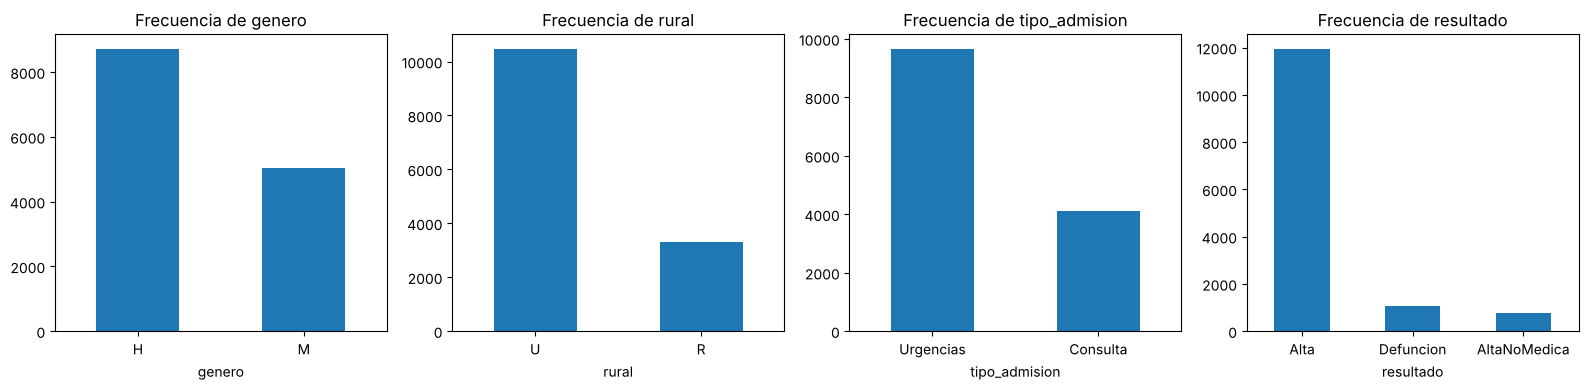

In [21]:
# Variables de texto. Se detectan así para que funcione igual en pandas 2 (tipo 'object') y en pandas 3 (tipo 'str')
categoricas_texto = [c for c in df.columns
                     if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_datetime64_any_dtype(df[c])]

fig, ejes = plt.subplots(1, len(categoricas_texto), figsize=(16, 4))
for eje, variable in zip(ejes, categoricas_texto):
    df[variable].value_counts().plot.bar(ax=eje, rot=0)
    eje.set_title(f'Frecuencia de {variable}')
plt.tight_layout()
plt.show()

**Mejora:** los 4 gráficos se dibujan en una sola figura (`plt.subplots`) para compararlos de un vistazo. En el original salía uno debajo de otro.

- Hay más hombres (63 %) que mujeres y más población urbana (76 %) que rural.
- 7 de cada 10 ingresos llegan por Urgencias.
- El resultado más frecuente es el alta (87 %); las defunciones son el 7,6 % de las admisiones y el alta no médica (voluntaria) el 5,6 %.

### 4.3 Variables numéricas

In [22]:
# Mejora: se seleccionan por tipo, no por posición (el original usaba df.iloc[:, 12:], que se saltaba tabaquismo y edad)
df.select_dtypes('number').drop(columns=['id_admision', 'id_paciente']).describe().T

,count,mean,std,min,25%,50%,75%,max
edad,13767.0,61.343793,13.428563,4.000,54.00,62.0,70.0000,110.00
duracion_estancia,13767.0,6.370378,5.035487,1.000,3.00,5.0,8.0000,98.00
duracion_estancia_ci,13767.0,3.777802,4.028964,0.000,1.00,3.0,5.0000,58.00
tabaquismo,13767.0,0.052880,0.223802,0.000,0.00,0.0,0.0000,1.00
alcohol,13767.0,0.067989,0.251736,0.000,0.00,0.0,0.0000,1.00
dm,13767.0,0.303116,0.459622,0.000,0.00,0.0,1.0000,1.00
hta,13767.0,0.484056,0.499764,0.000,0.00,0.0,1.0000,1.00
eac,13767.0,0.665650,0.471780,0.000,0.00,1.0,1.0000,1.00
cardiomiopatia_previa,13767.0,0.323455,0.467812,0.000,0.00,0.0,1.0000,1.00
erc,13767.0,0.315900,0.464890,0.000,0.00,0.0,1.0000,1.00


Lectura:

- Casi todas las variables numéricas son **indicadores 0/1** (factores de riesgo y diagnósticos): su media es directamente el % de admisiones que los tienen. Por ejemplo, la media de `insuficiencia_cardiaca` es la proporción de admisiones con ese diagnóstico.
- **Valores llamativos en laboratorio**: plaquetas con un mínimo de 0,58 (lo normal es 150-400 mil/µL, así que parece un dato en otra unidad), BNP con 83 valores exactamente en 5.000 (el **tope** de medida del análisis) y fracción de eyección con un máximo de exactamente 60 (probablemente se registró "≥ 60 %" como 60). No son errores que haya que corregir, pero sí topes que conviene conocer.

## 5. Variable objetivo: el reingreso (`03_Minicubo_y_RSC`)

### 5.1 La definición original

El original marcaba como reingreso **toda admisión que no es la primera del paciente**:

In [23]:
# Ordenar por paciente y fecha (con id_admision para desempatar ingresos del mismo día)
df = df.sort_values(['id_paciente', 'fecha_admision', 'id_admision']).reset_index(drop=True)

# Reingreso (definición original): el paciente de esta fila es el mismo que el de la fila anterior
df['reingreso'] = (df['id_paciente'] == df['id_paciente'].shift(1)).astype(int)

df[['id_admision', 'id_paciente', 'fecha_admision', 'fecha_alta', 'resultado', 'reingreso']].head(10)

,id_admision,id_paciente,fecha_admision,fecha_alta,resultado,reingreso
0,15196,506,2024-03-07,2024-03-10,Alta,0
1,93,798,2022-04-05,2022-04-06,Alta,0
2,3526,798,2022-05-10,2022-05-11,Alta,1
3,15111,798,2024-03-04,2024-03-09,Alta,1
4,12720,989,2023-05-12,2023-05-14,Alta,0
5,11477,989,2023-10-15,2023-10-17,Alta,1
6,6500,1006,2023-09-02,2023-10-29,Defuncion,0
7,4033,1060,2022-11-01,2022-11-02,Alta,0
8,4386,1196,2022-11-13,2022-11-21,Alta,0
9,8587,1261,2023-05-26,2023-05-28,Alta,0


`shift(1)` desplaza la columna una fila hacia abajo. Así cada fila "ve" el paciente de la fila anterior; si es el mismo, esta admisión es un reingreso. Como los datos están ordenados por paciente y fecha, la primera admisión de cada paciente siempre tiene `reingreso = 0`.

**Corrección (error 15):** se añade `id_admision` al ordenar. Si un paciente tiene dos ingresos en la misma fecha, sin desempate el orden entre ellos depende de cómo estuvieran los datos al leerlos, y puede cambiar de una ejecución a otra.

In [24]:
# ¿Qué porcentaje de admisiones son reingresos?
df.reingreso.mean() * 100

np.float64(14.31684462845936)

**Análisis a nivel de paciente**

In [25]:
reingresos_pacientes = df.groupby('id_paciente').reingreso.sum()
reingresos_pacientes_agr = reingresos_pacientes.value_counts().sort_index()
reingresos_pacientes_agr

reingreso
0     10299
1      1189
2       224
3        46
4        22
5         7
6         4
7         1
8         1
10        1
11        1
13        1
Name: count, dtype: int64

In [26]:
# ¿Qué porcentaje de pacientes tiene al menos un reingreso?
(1 - reingresos_pacientes_agr[0] / reingresos_pacientes_agr.sum()) * 100

np.float64(12.690742624618512)

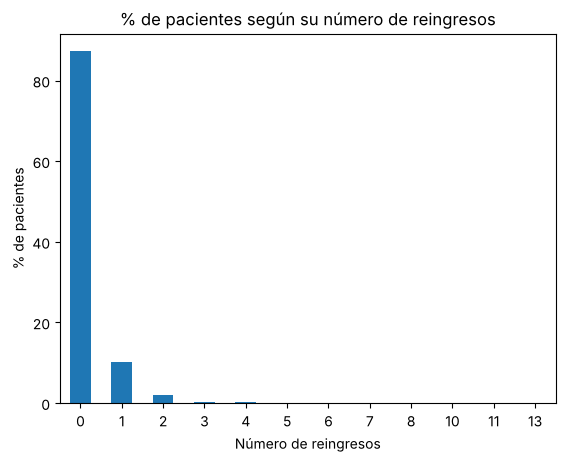

reingreso
0     87.31
1     10.08
2      1.90
3      0.39
4      0.19
5      0.06
6      0.03
7      0.01
8      0.01
10     0.01
11     0.01
13     0.01
Name: count, dtype: float64

In [27]:
# Distribución de los reingresos (% de pacientes)
reingresos_pacientes_agr_porc = reingresos_pacientes_agr / reingresos_pacientes_agr.sum() * 100
ax = reingresos_pacientes_agr_porc.plot.bar(rot=0, title='% de pacientes según su número de reingresos')
ax.set_xlabel('Número de reingresos')
ax.set_ylabel('% de pacientes')
plt.show()
reingresos_pacientes_agr_porc.round(2)

El 87,3 % de los pacientes no reingresa nunca y el 10,1 % reingresa una vez. Unos pocos acumulan muchos ingresos (hasta 13 reingresos): son crónicos con descompensaciones frecuentes. En el original salía un 20,6 % de pacientes con algún reingreso; la diferencia son los duplicados.

### 5.2 Corrección (error 5): ¿cuánto tiempo después?

La definición original cuenta como reingreso cualquier ingreso posterior, aunque sea 2 años después. Se mira cuántos días pasan entre el alta y el siguiente ingreso:

count    1971.0
mean      128.8
std       139.0
min       -52.0
25%        19.0
50%        77.0
75%       204.0
max       704.0
Name: dias_hasta_siguiente, dtype: float64


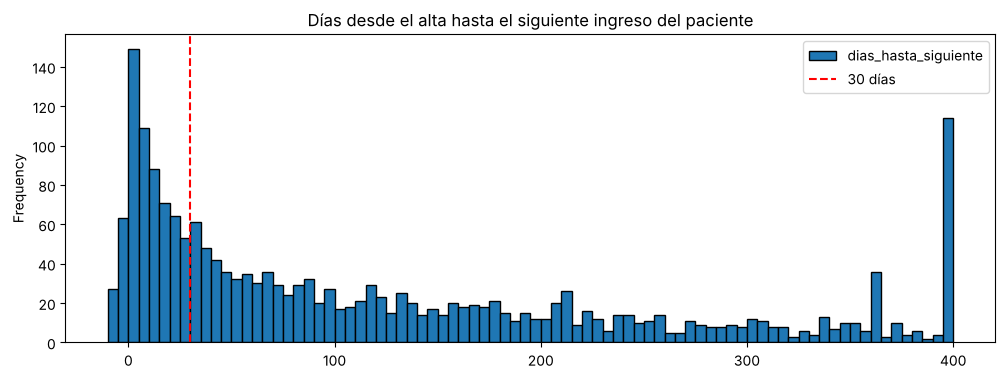

In [28]:
df['siguiente_ingreso'] = df.groupby('id_paciente')['fecha_admision'].shift(-1)
df['dias_hasta_siguiente'] = (df['siguiente_ingreso'] - df['fecha_alta']).dt.days

print(df['dias_hasta_siguiente'].describe().round(1))

ax = df['dias_hasta_siguiente'].clip(-10, 400).plot.hist(bins=82, figsize=(12, 4), edgecolor='black',
                                                         title='Días desde el alta hasta el siguiente ingreso del paciente')
ax.axvline(30, color='red', linestyle='--', label='30 días')
ax.legend()
plt.show()

La mediana es de **77 días** y una cuarta parte de los siguientes ingresos llega más de 200 días después. Un ingreso a los 600 días casi nunca tiene que ver con cómo se dio el alta anterior.

El indicador estándar en hospitales es el **reingreso a 30 días**: un nuevo ingreso del mismo paciente en los 30 días siguientes al alta. Es el que se usa para medir la calidad asistencial, porque es el que se puede evitar con un mejor alta y seguimiento.

Hay un segundo problema, la **censura por la derecha**: los datos acaban el 31 de marzo de 2024. Un paciente dado de alta el 25 de marzo no ha tenido tiempo de reingresar, y con la definición original aparece como "no genera reingreso" aunque reingrese el 2 de abril. Hay que excluir del modelo las altas que no tienen el periodo de seguimiento completo.

**La ventana se define como parámetro.** Con `VENTANA_DIAS = 30` se usa el reingreso a 30 días; con `VENTANA_DIAS = None` se recupera la definición original (cualquier ingreso posterior), por si en el curso se pide así.

In [29]:
VENTANA_DIAS = 30                                # None = cualquier ingreso posterior (definición original)
FECHA_FIN_DATOS = df['fecha_admision'].max()     # último día con ingresos registrados

def calcular_genera_reingreso(dias_hasta_siguiente, ventana=VENTANA_DIAS):
    # 1 si el paciente vuelve a ingresar después del alta (dentro de la ventana), 0 si no
    # dias < 0: el siguiente ingreso empieza antes del alta (solapado): no cuenta como reingreso
    if ventana is None:
        return (dias_hasta_siguiente >= 0).astype(int)
    return ((dias_hasta_siguiente >= 0) & (dias_hasta_siguiente <= ventana)).astype(int)

df['genera_reingreso'] = calcular_genera_reingreso(df['dias_hasta_siguiente'])

# ¿Tiene esta alta el seguimiento completo? (si no hay ventana, todas las altas lo tienen por definición)
if VENTANA_DIAS is None:
    df['seguimiento_completo'] = True
else:
    df['seguimiento_completo'] = df['fecha_alta'] <= FECHA_FIN_DATOS - pd.Timedelta(days=VENTANA_DIAS)

print('Último ingreso registrado:', FECHA_FIN_DATOS.date())
print('Altas sin seguimiento completo:', (~df['seguimiento_completo']).sum())
df[['id_admision', 'id_paciente', 'fecha_admision', 'fecha_alta', 'reingreso', 'dias_hasta_siguiente', 'genera_reingreso']].head(10)

Último ingreso registrado: 2024-03-31
Altas sin seguimiento completo: 595


,id_admision,id_paciente,fecha_admision,fecha_alta,reingreso,dias_hasta_siguiente,genera_reingreso
0,15196,506,2024-03-07,2024-03-10,0,NaN,0
1,93,798,2022-04-05,2022-04-06,0,34.0,0
2,3526,798,2022-05-10,2022-05-11,1,663.0,0
3,15111,798,2024-03-04,2024-03-09,1,NaN,0
4,12720,989,2023-05-12,2023-05-14,0,154.0,0
5,11477,989,2023-10-15,2023-10-17,1,NaN,0
6,6500,1006,2023-09-02,2023-10-29,0,NaN,0
7,4033,1060,2022-11-01,2022-11-02,0,NaN,0
8,4386,1196,2022-11-13,2022-11-21,0,NaN,0
9,8587,1261,2023-05-26,2023-05-28,0,NaN,0


Cómo funciona:

- `groupby('id_paciente')['fecha_admision'].shift(-1)` trae a cada fila la fecha del **siguiente** ingreso del **mismo** paciente. Al hacerse dentro del `groupby`, la última admisión de un paciente nunca "ve" la del paciente siguiente: queda `NaT`.
- `dias_hasta_siguiente` son los días entre el alta y ese siguiente ingreso. Las comparaciones con `NaT`/`NaN` dan `False`, así que la última admisión de cada paciente queda con 0.

El original hacía `risk['genera_reingreso'] = risk.reingreso.shift(-1)`, sin `groupby`. Era correcto con su definición, aunque por casualidad: `reingreso` de la fila siguiente solo vale 1 si esa fila es del mismo paciente. Aquí se calcula de forma explícita, que es más fácil de leer y permite añadir la ventana de días.

### 5.3 Población del modelo

Se quitan dos grupos:

- **Defunciones.** Un paciente que fallece en el ingreso no puede reingresar, por mucho riesgo que tuviera. Si se dejara, sus características (que suelen ser de alto riesgo) aparecerían como "no generan reingreso" y confundirían al modelo. Si interesara la mortalidad, se haría este mismo análisis con la defunción como objetivo.
- **Altas sin seguimiento completo** (censura).

In [30]:
risk = df[(df['resultado'] != 'Defuncion') & df['seguimiento_completo']].copy()
print('Admisiones en el modelo:', len(risk))
print(risk['resultado'].value_counts())
print(f"\nTasa de reingreso a {VENTANA_DIAS} días: {risk['genera_reingreso'].mean() * 100:.2f} %")

Admisiones en el modelo: 12156
resultado
Alta            11430
AltaNoMedica      726
Name: count, dtype: int64

Tasa de reingreso a 30 días: 4.48 %


**Cuánto cambia la definición:** se compara la tasa de reingreso del modelo con la definición original (con y sin los duplicados) y con la corregida.

In [31]:
# Recalculamos la definición original sobre los datos SIN quitar duplicados, solo para comparar
original = pacientes.merge(admisiones.drop(columns=['id_paciente']), on='id_admision').sort_values(['id_paciente', 'fecha_admision'])
original['reingreso'] = (original['id_paciente'] == original['id_paciente'].shift(1)).astype(int)
original['genera_reingreso'] = original['reingreso'].shift(-1)
original = original[original['resultado'] != 'Defuncion']

sin_dup = df[df['resultado'] != 'Defuncion']
pd.DataFrame({
    'admisiones': [len(original), len(sin_dup), len(risk)],
    'tasa_reingreso_%': [original['genera_reingreso'].mean() * 100,
                         (sin_dup['dias_hasta_siguiente'] >= 0).mean() * 100,
                         risk['genera_reingreso'].mean() * 100],
}, index=['Original (cualquier ingreso posterior, con duplicados)',
          'Cualquier ingreso posterior, sin duplicados',
          f'Corregida: reingreso a {VENTANA_DIAS} días, sin duplicados ni censura']).round(2)

,admisiones,tasa_reingreso_%
"Original (cualquier ingreso posterior, con duplicados)",13984,23.13
"Cualquier ingreso posterior, sin duplicados",12719,14.77
"Corregida: reingreso a 30 días, sin duplicados ni censura",12156,4.48


La tasa pasa del **23,1 %** original al **14,8 %** al quitar duplicados y solapes, y al **4,5 %** con el reingreso a 30 días. Es una tasa de reingreso a 30 días baja para cardiología (en la literatura suele estar entre el 10 y el 20 %), pero los datos son los que son. El modelo tiene que encontrar ahora un suceso **más raro** y más relacionado con el alta.

### 5.4 Separar desarrollo y prueba (error 10)

**Corrección.** En el original, las variables se elegían, los puntos se calculaban y el resultado se comprobaba **con los mismos datos**. Es como corregir un examen con las respuestas delante: siempre sale bien. Para saber si el scorecard funciona con pacientes nuevos hay que guardar datos que el modelo no vea.

Se hace un **corte temporal**, que es como funcionará en la realidad (se construye con el pasado y se aplica al futuro):

- **Desarrollo:** admisiones hasta el 30 de junio de 2023.
- **Prueba:** admisiones desde el 1 de julio de 2023.

Todas las decisiones (qué variables entran, dónde se corta cada tramo, cuántos puntos vale cada categoría) se toman **solo con desarrollo**.

In [32]:
FECHA_CORTE = pd.Timestamp('2023-07-01')

desarrollo = risk[risk['fecha_admision'] < FECHA_CORTE].copy()
prueba = risk[risk['fecha_admision'] >= FECHA_CORTE].copy()

for nombre, parte in [('Desarrollo', desarrollo), ('Prueba', prueba)]:
    print(f"{nombre:11s} {len(parte):6d} admisiones  {parte['fecha_admision'].min().date()} a {parte['fecha_admision'].max().date()}"
          f"  tasa de reingreso {parte['genera_reingreso'].mean() * 100:.2f} %")

Desarrollo    7793 admisiones  2022-04-01 a 2023-06-30  tasa de reingreso 4.50 %
Prueba        4363 admisiones  2023-07-01 a 2024-02-28  tasa de reingreso 4.42 %


## 6. Selección de variables (`03_Minicubo_y_RSC`)

Hay 50 variables candidatas. El *scorecard* debe ser sencillo, así que se eligen las que más se relacionan con el reingreso:

- **Categóricas y 0/1:** prueba **chi-cuadrado**, que mide si el % de reingreso es distinto entre las categorías de la variable. Cuanto mayor el valor chi², más fuerte la relación.
- **Continuas:** prueba **t de Student**, que mide si la media de la variable es distinta entre los que reingresan y los que no.

Se eliminan antes las variables que no tienen sentido como predictores: los identificadores, las fechas y las columnas auxiliares creadas en el paso 5.

In [33]:
eliminar = ['id_admision', 'id_paciente', 'fecha_admision', 'fecha_alta', 'reingreso',
            'siguiente_ingreso', 'dias_hasta_siguiente', 'seguimiento_completo']
risk2 = desarrollo.drop(columns=eliminar)
risk2.info()

<class 'pandas.DataFrame'>
Index: 7793 entries, 1 to 13764
Data columns (total 52 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   edad                       7793 non-null   int64  
 1   genero                     7793 non-null   str    
 2   rural                      7793 non-null   str    
 3   tipo_admision              7793 non-null   str    
 4   duracion_estancia          7793 non-null   int64  
 5   duracion_estancia_ci       7793 non-null   int64  
 6   resultado                  7793 non-null   str    
 7   tabaquismo                 7793 non-null   int64  
 8   alcohol                    7793 non-null   int64  
 9   dm                         7793 non-null   int64  
 10  hta                        7793 non-null   int64  
 11  eac                        7793 non-null   int64  
 12  cardiomiopatia_previa      7793 non-null   int64  
 13  erc                        7793 non-null   int64  
 14  hb     

In [34]:
descriptivos = risk2.describe().T

# Variables 0/1 (mínimo 0 y máximo 1), sin la propia variable objetivo
cero_uno = [v for v in descriptivos[(descriptivos['min'] == 0) & (descriptivos['max'] == 1)].index if v != 'genera_reingreso']

# Variables de texto
texto = [c for c in risk2.columns if not pd.api.types.is_numeric_dtype(risk2[c])]

categoricas = texto + cero_uno
print(len(categoricas), 'categóricas:', categoricas)

40 categóricas: ['genero', 'rural', 'tipo_admision', 'resultado', 'tabaquismo', 'alcohol', 'dm', 'hta', 'eac', 'cardiomiopatia_previa', 'erc', 'enzimas_elevadas', 'anemia_severa', 'anemia', 'angina_estable', 'sca', 'iamcest', 'dolor_toracico', 'insuficiencia_cardiaca', 'icfer', 'icfen', 'valvular_cardiaca', 'bavc', 'sse', 'lra', 'acv_infarto', 'acv_hemorragia', 'fa', 'tv', 'tsvp', 'cardiopatia_congenita', 'itu', 'sincope_neurocardiogenico', 'hipotension_ortostatica', 'endocarditis_infecciosa', 'tvp', 'shock_cardiogenico', 'shock', 'embolia_pulmonar', 'infeccion_pulmonar']


**Corrección (error 11):** el original incluía `genera_reingreso` en la lista de categóricas (también es 0/1), y por eso el primer puesto del ranking era la propia variable objetivo, con un chi² enorme. Se saltaba empezando en `[1:10]`. Aquí se excluye al construir la lista, que es más seguro.

**Chi-cuadrado para las categóricas**

In [35]:
def chi_square_test(df, target_col, categorical_col):
    # Tabla de contingencia (categoría x reingreso) sin los nulos de esa variable
    df_filtrado = df.dropna(subset=[categorical_col])
    tabla_contingencia = pd.crosstab(df_filtrado[categorical_col], df_filtrado[target_col])
    chi2, p, dof, expected = chi2_contingency(tabla_contingencia)
    return chi2, p

resultados = {var: chi_square_test(risk2, 'genera_reingreso', var) for var in categoricas}
ranking = pd.DataFrame(resultados, index=['Chi2', 'P-valor']).T.sort_values('Chi2', ascending=False)
ranking.head(15)

,Chi2,P-valor
insuficiencia_cardiaca,330.935198,6.013133e-74
icfen,303.093381,6.979739e-68
icfer,285.509472,4.731815e-64
cardiomiopatia_previa,257.272312,6.746815e-58
lra,253.867465,3.726686e-57
erc,239.709769,4.549765e-54
iamcest,188.703454,6.100198e-43
dm,181.352770,2.455058e-41
sca,140.795431,1.783507e-32
tipo_admision,9.498503,2.056396e-03


In [36]:
ranking[ranking['P-valor'] <= 0.01]

,Chi2,P-valor
insuficiencia_cardiaca,330.935198,6.013133e-74
icfen,303.093381,6.979739e-68
icfer,285.509472,4.731815e-64
cardiomiopatia_previa,257.272312,6.746815e-58
lra,253.867465,3.726686e-57
erc,239.709769,4.549765e-54
iamcest,188.703454,6.100198e-43
dm,181.352770,2.455058e-41
sca,140.795431,1.783507e-32
tipo_admision,9.498503,2.056396e-03


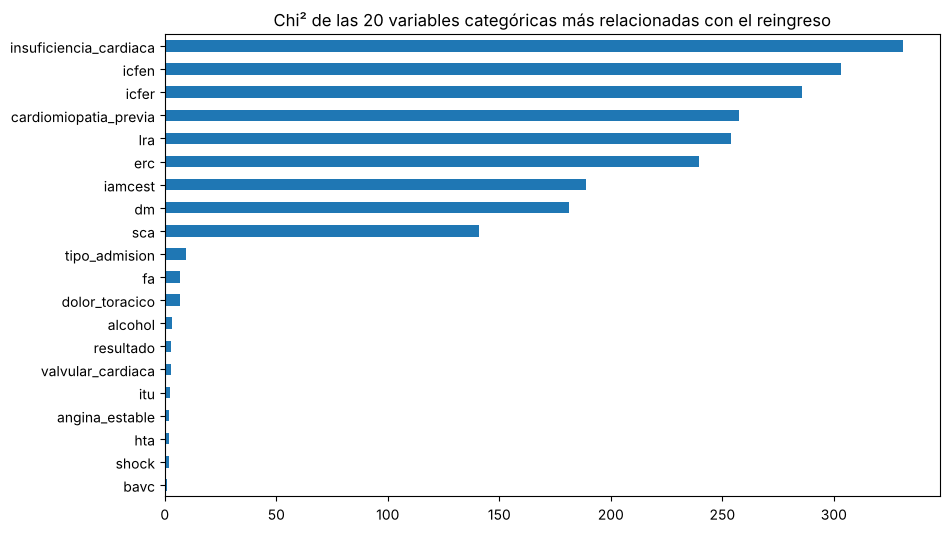

In [37]:
ax = ranking['Chi2'].head(20).plot.barh(figsize=(10, 6), title='Chi² de las 20 variables categóricas más relacionadas con el reingreso')
ax.invert_yaxis()
plt.show()

Hay un **corte muy claro**: 9 variables tienen un chi² entre 140 y 330, y la siguiente cae por debajo de 10. Son las mismas 9 del original (con un orden ligeramente distinto). Se seleccionan esas 9.

In [38]:
N_CATEGORICAS = 9
significativas_cat = ranking.index[:N_CATEGORICAS].to_list()
significativas_cat

['insuficiencia_cardiaca',
 'icfen',
 'icfer',
 'cardiomiopatia_previa',
 'lra',
 'erc',
 'iamcest',
 'dm',
 'sca']

**t de Student para las continuas**

**Mejora:** se usa `equal_var=False` (prueba de Welch). La t clásica supone que los dos grupos tienen la misma varianza, y aquí hay muchos menos reingresos que no reingresos. Welch no necesita ese supuesto y es la recomendada por defecto.

In [39]:
continuas = [c for c in risk2.columns if c not in categoricas + ['genera_reingreso']]

filas = []
for col in continuas:
    sin_nulos = risk2.dropna(subset=[col])
    grupo_no = sin_nulos.loc[sin_nulos['genera_reingreso'] == 0, col]
    grupo_si = sin_nulos.loc[sin_nulos['genera_reingreso'] == 1, col]
    if len(grupo_no) > 30 and len(grupo_si) > 30:
        t_stat, p_valor = ttest_ind(grupo_no, grupo_si, equal_var=False)
        filas.append({'variable': col, 'media_no_reingresa': grupo_no.mean(), 'media_reingresa': grupo_si.mean(),
                      't': t_stat, 'p_valor': p_valor})

pruebas_t = pd.DataFrame(filas).set_index('variable').sort_values('p_valor')
pruebas_t['diagnostico'] = np.where(pruebas_t['p_valor'] < 0.01, 'Significativa', 'No significativa')
pruebas_t

,media_no_reingresa,media_reingresa,t,p_valor,diagnostico
variable,,,,,
urea,46.328392,58.860399,-4.514092,0.000009,Significativa
edad,60.614620,63.572650,-4.416467,0.000013,Significativa
duracion_estancia_ci,3.565171,4.683761,-4.285292,0.000023,Significativa
duracion_estancia,6.391696,7.997151,-4.108905,0.000049,Significativa
fe,43.540000,40.283912,4.105258,0.000050,Significativa
hb,12.445530,12.006838,3.705618,0.000242,Significativa
creatinina,1.294828,1.523686,-3.302742,0.001049,Significativa
bnp,802.288579,1108.934167,-2.758791,0.006658,Significativa
glucosa,162.626375,171.780120,-1.835700,0.067228,No significativa


**Corrección (error 9).** El original decía "nos quedaremos con las 3 continuas más significativas", pero hacía `significativas_con[:3]`: las 3 primeras de la lista, que estaba **en el orden de las columnas** (edad, duracion_estancia, duracion_estancia_ci). Aquí la tabla está ordenada por p-valor, así que las 3 primeras sí son las más significativas.

Lectura: los que reingresan son algo mayores, tienen la urea más alta (peor función renal), más días en cuidados intensivos y la fracción de eyección más baja (el corazón bombea peor). Todo tiene sentido clínico.

In [40]:
N_CONTINUAS = 3
significativas_con = pruebas_t[pruebas_t['diagnostico'] == 'Significativa'].index[:N_CONTINUAS].to_list()

significativas = significativas_cat + significativas_con
significativas

['insuficiencia_cardiaca',
 'icfen',
 'icfer',
 'cardiomiopatia_previa',
 'lra',
 'erc',
 'iamcest',
 'dm',
 'sca',
 'urea',
 'edad',
 'duracion_estancia_ci']

## 7. Minicubo (`03_Minicubo_y_RSC`)

Pasos:

1. Reducir la dimensión a las variables significativas (hecho en el paso 6).
2. Convertir las variables continuas en categóricas (tramos).
3. Pasar a formato transaccional (una fila por admisión y variable).
4. Calcular la penetración del reingreso en cada variable-valor.

### 7.1 Discretización de las continuas

El original miraba un histograma normalizado (cada barra al 100 %, con el % de reingreso de cada tramo) y elegía los cortes a ojo. Se mantiene el gráfico para entender cada variable:

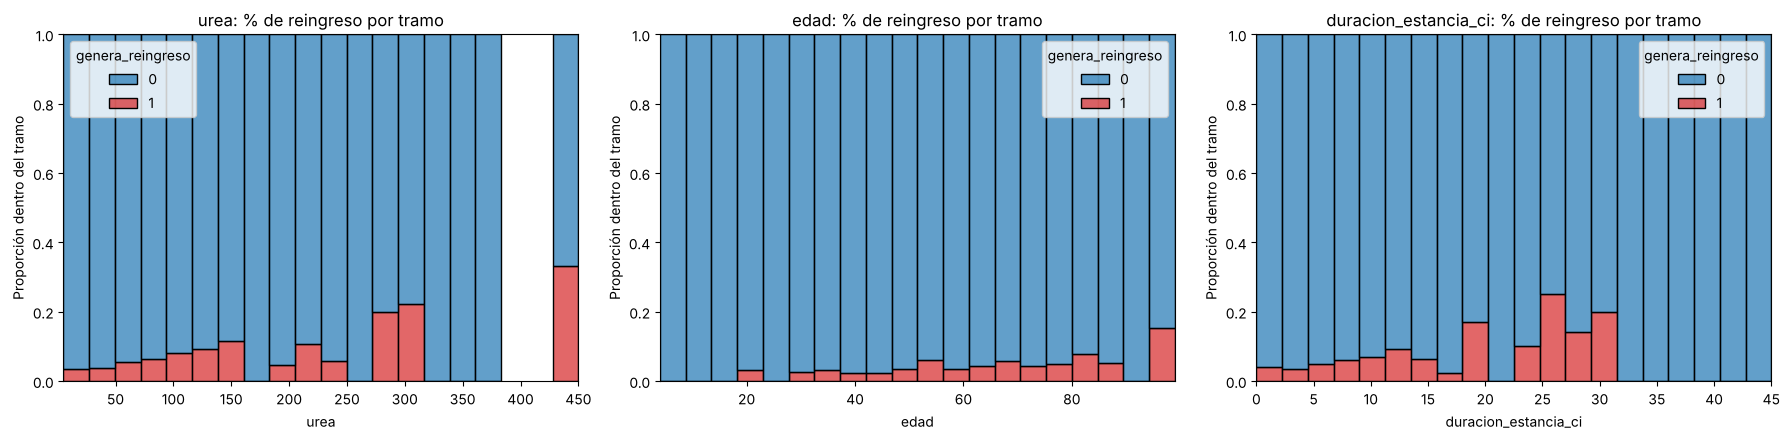

In [41]:
fig, ejes = plt.subplots(1, len(significativas_con), figsize=(18, 4.5))
for eje, variable in zip(ejes, significativas_con):
    sns.histplot(data=risk2, x=variable, hue='genera_reingreso', bins=20, stat='percent',
                 multiple='fill', palette=['tab:blue', 'tab:red'], edgecolor='k', alpha=0.7, ax=eje)
    eje.set_title(f'{variable}: % de reingreso por tramo')
    eje.set_ylabel('Proporción dentro del tramo')
plt.tight_layout()
plt.show()

`multiple='fill'` pone todas las barras a la misma altura (100 %). Así no importa cuántos pacientes hay en cada tramo: solo se ve **qué parte** de cada tramo reingresa (en rojo).

**Corrección de la leyenda:** en el original la leyenda tenía las etiquetas cambiadas (`labels=['% Reingresos', '% No reingresos']`). Seaborn dibuja primero el 0 y después el 1, y forzar las etiquetas a mano las asignaba al revés. Aquí se deja la leyenda que genera Seaborn (0 = no reingresa, 1 = reingresa).

**Mejora: cortes por quintiles en lugar de a ojo.** Los cortes manuales tienen dos problemas. Dependen de quien mira el gráfico, y algunos tramos se quedan con muy pocos pacientes. Por ejemplo, en el original el tramo de estancia de 60 a 100 días tenía 1 o 2 casos y le daba 100 puntos, el máximo de toda la tabla, por **un solo paciente**. Con **quintiles** (`qcut` en 5 grupos) cada tramo tiene el 20 % de los pacientes de desarrollo, y su % de reingreso es fiable. Los cortes se calculan **solo con desarrollo** y se guardan para aplicarlos tal cual a prueba y a producción.

Los extremos se dejan abiertos (`-inf` e `inf`), para que un valor nuevo más alto o más bajo que todos los de desarrollo caiga en el primer o en el último tramo en lugar de quedar fuera.

In [42]:
def calcular_cortes(serie, n_tramos=5):
    # Cortes por cuantiles (sin repetir), con los extremos abiertos
    cortes = np.unique(np.quantile(serie.dropna(), np.linspace(0, 1, n_tramos + 1)))
    return [-np.inf] + list(cortes[1:-1]) + [np.inf]

def tramificar(serie, cortes):
    # Convierte una variable continua en texto con su tramo; los nulos pasan a 'Sin dato'
    tramos = pd.cut(serie, bins=cortes).astype(str)
    return tramos.where(serie.notna(), 'Sin dato')

cortes = {variable: calcular_cortes(risk2[variable]) for variable in significativas_con}
for variable, c in cortes.items():
    print(f'{variable:22s}', c)

urea                   [-inf, np.float64(23.0), np.float64(30.0), np.float64(39.0), np.float64(60.0), inf]
edad                   [-inf, np.float64(50.0), np.float64(58.0), np.float64(65.0), np.float64(72.0), inf]
duracion_estancia_ci   [-inf, np.float64(2.0), np.float64(4.0), np.float64(6.0), inf]


Si una variable tiene muchos valores repetidos, dos cuantiles pueden coincidir (por ejemplo, el 20 % y el 40 % de `duracion_estancia_ci` pueden ser los dos 1 día). `np.unique` elimina los cortes repetidos y la variable se queda con menos tramos.

`tramificar` hace dos cosas:

1. `pd.cut(...).astype(str)` convierte el tramo en **texto**, por ejemplo `'(58.0, 65.0]'`. En el original los tramos se quedaban como objetos `Interval`, y por eso la comparación con `"(0, 10]"` de la función de scoring nunca se cumplía (error 6).
2. `where(serie.notna(), 'Sin dato')`: los nulos se convierten en una categoría propia. En un scorecard "no se le hizo la analítica" también puede aportar información.

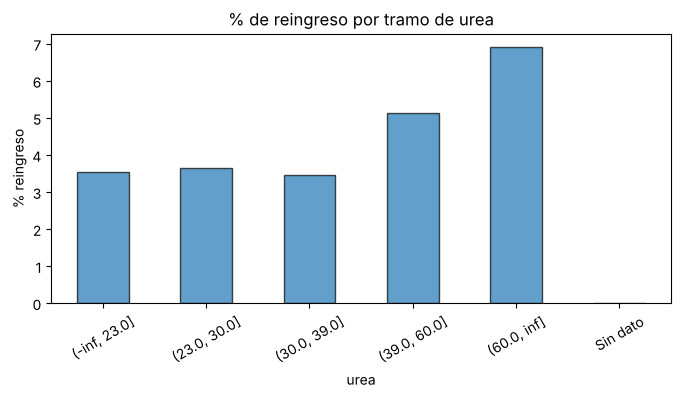

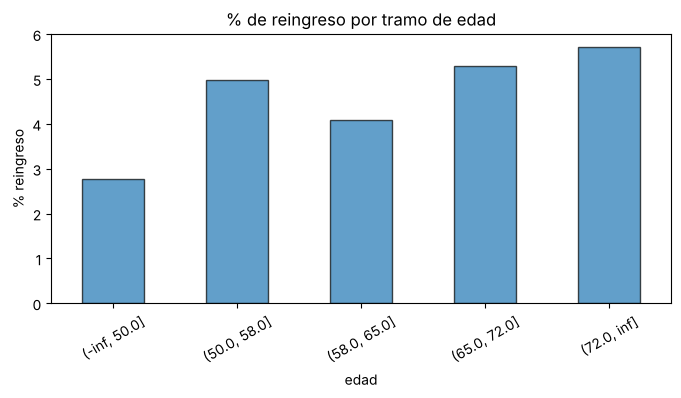

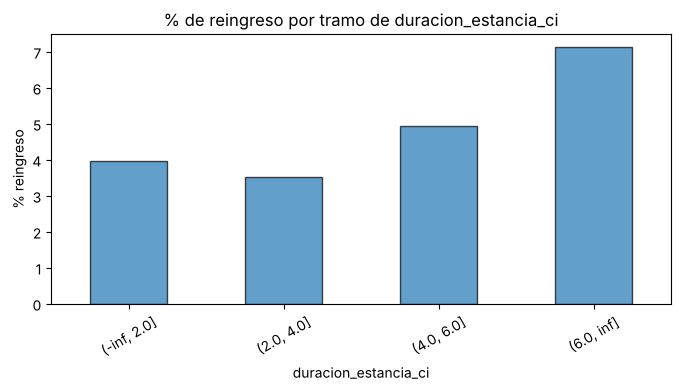

In [43]:
for variable in significativas_con:
    tramo = tramificar(risk2[variable], cortes[variable])
    (risk2.groupby(tramo)['genera_reingreso'].mean() * 100).plot.bar(
        rot=30, edgecolor='k', alpha=0.7, figsize=(8, 3.5), title=f'% de reingreso por tramo de {variable}')
    plt.ylabel('% reingreso')
    plt.show()

### 7.2 Crear el minicubo

Se queda con las variables significativas, se sustituyen las continuas por sus tramos y se pasa a formato **transaccional** con `melt`.

In [44]:
def preparar_minicubo(datos):
    # Tabla con las variables del scorecard ya como texto: 0/1 de las categóricas y tramos de las continuas
    salida = pd.DataFrame(index=datos.index)
    for variable in significativas_cat:
        salida[variable] = datos[variable].astype(str)
    for variable in significativas_con:
        salida[variable] = tramificar(datos[variable], cortes[variable])
    return salida

minicubo = preparar_minicubo(risk2)
minicubo['genera_reingreso'] = risk2['genera_reingreso']
minicubo

,insuficiencia_cardiaca,icfen,icfer,cardiomiopatia_previa,lra,erc,iamcest,dm,sca,urea,edad,duracion_estancia_ci,genera_reingreso
1,1,1,0,1,0,1,1,1,0,"(30.0, 39.0]","(65.0, 72.0]","(-inf, 2.0]",0
2,1,0,1,0,0,0,0,0,0,"(30.0, 39.0]","(65.0, 72.0]","(-inf, 2.0]",0
4,0,1,1,1,1,0,1,1,1,"(39.0, 60.0]","(65.0, 72.0]","(2.0, 4.0]",0
7,0,0,0,0,0,0,0,1,0,"(23.0, 30.0]","(65.0, 72.0]","(-inf, 2.0]",0
8,0,0,1,0,0,0,0,0,1,"(23.0, 30.0]","(65.0, 72.0]","(-inf, 2.0]",0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
13755,1,0,1,1,0,0,0,0,0,"(-inf, 23.0]","(-inf, 50.0]","(4.0, 6.0]",0
13756,1,0,1,1,1,1,0,0,1,"(60.0, inf]","(72.0, inf]","(4.0, 6.0]",0
13757,0,1,1,0,1,1,1,1,0,"(23.0, 30.0]","(50.0, 58.0]","(-inf, 2.0]",0
13758,0,0,0,0,1,0,1,0,0,"(30.0, 39.0]","(-inf, 50.0]","(-inf, 2.0]",0


In [45]:
# Pasamos a formato transaccional: una fila por admisión y variable
minicubo = minicubo.melt(id_vars='genera_reingreso')
minicubo

,genera_reingreso,variable,value
0,0,insuficiencia_cardiaca,1
1,0,insuficiencia_cardiaca,1
2,0,insuficiencia_cardiaca,0
3,0,insuficiencia_cardiaca,0
4,0,insuficiencia_cardiaca,0
...,...,...,...
93511,0,duracion_estancia_ci,"(4.0, 6.0]"
93512,0,duracion_estancia_ci,"(4.0, 6.0]"
93513,0,duracion_estancia_ci,"(-inf, 2.0]"
93514,0,duracion_estancia_ci,"(-inf, 2.0]"


`melt` pasa de **ancho** (una columna por variable) a **largo** (una fila por admisión y variable, con las columnas `variable` y `value`). Así se puede calcular la penetración de todas las variables de una vez con un solo `groupby`.

En el original, después del `melt` había que convertir `value` a texto, porque mezclaba números (0/1) con intervalos. Aquí ya es todo texto desde `preparar_minicubo`.

In [46]:
# Penetración del reingreso en cada variable-valor
minicubo = minicubo.groupby(['variable', 'value']).agg(
    admisiones=('genera_reingreso', 'size'),
    genera_reingreso=('genera_reingreso', 'mean'),
).reset_index()
minicubo

,variable,value,admisiones,genera_reingreso
0,cardiomiopatia_previa,0,5177,0.018157
1,cardiomiopatia_previa,1,2616,0.098242
2,dm,0,5383,0.023779
3,dm,1,2410,0.092531
4,duracion_estancia_ci,"(-inf, 2.0]",3703,0.039698
5,duracion_estancia_ci,"(2.0, 4.0]",1704,0.035211
6,duracion_estancia_ci,"(4.0, 6.0]",1194,0.049414
7,duracion_estancia_ci,"(6.0, inf]",1192,0.071309
8,edad,"(-inf, 50.0]",1586,0.027743
9,edad,"(50.0, 58.0]",1547,0.049774


`genera_reingreso` es ahora la **penetración**: la proporción de admisiones de esa categoría que reingresan. Por ejemplo, si con `insuficiencia_cardiaca = 1` vale 0,10, el 10 % de las admisiones con insuficiencia cardiaca reingresa en 30 días.

**Mejora:** se añade la columna `admisiones`, para ver en qué categorías hay pocos casos y su penetración es menos fiable.

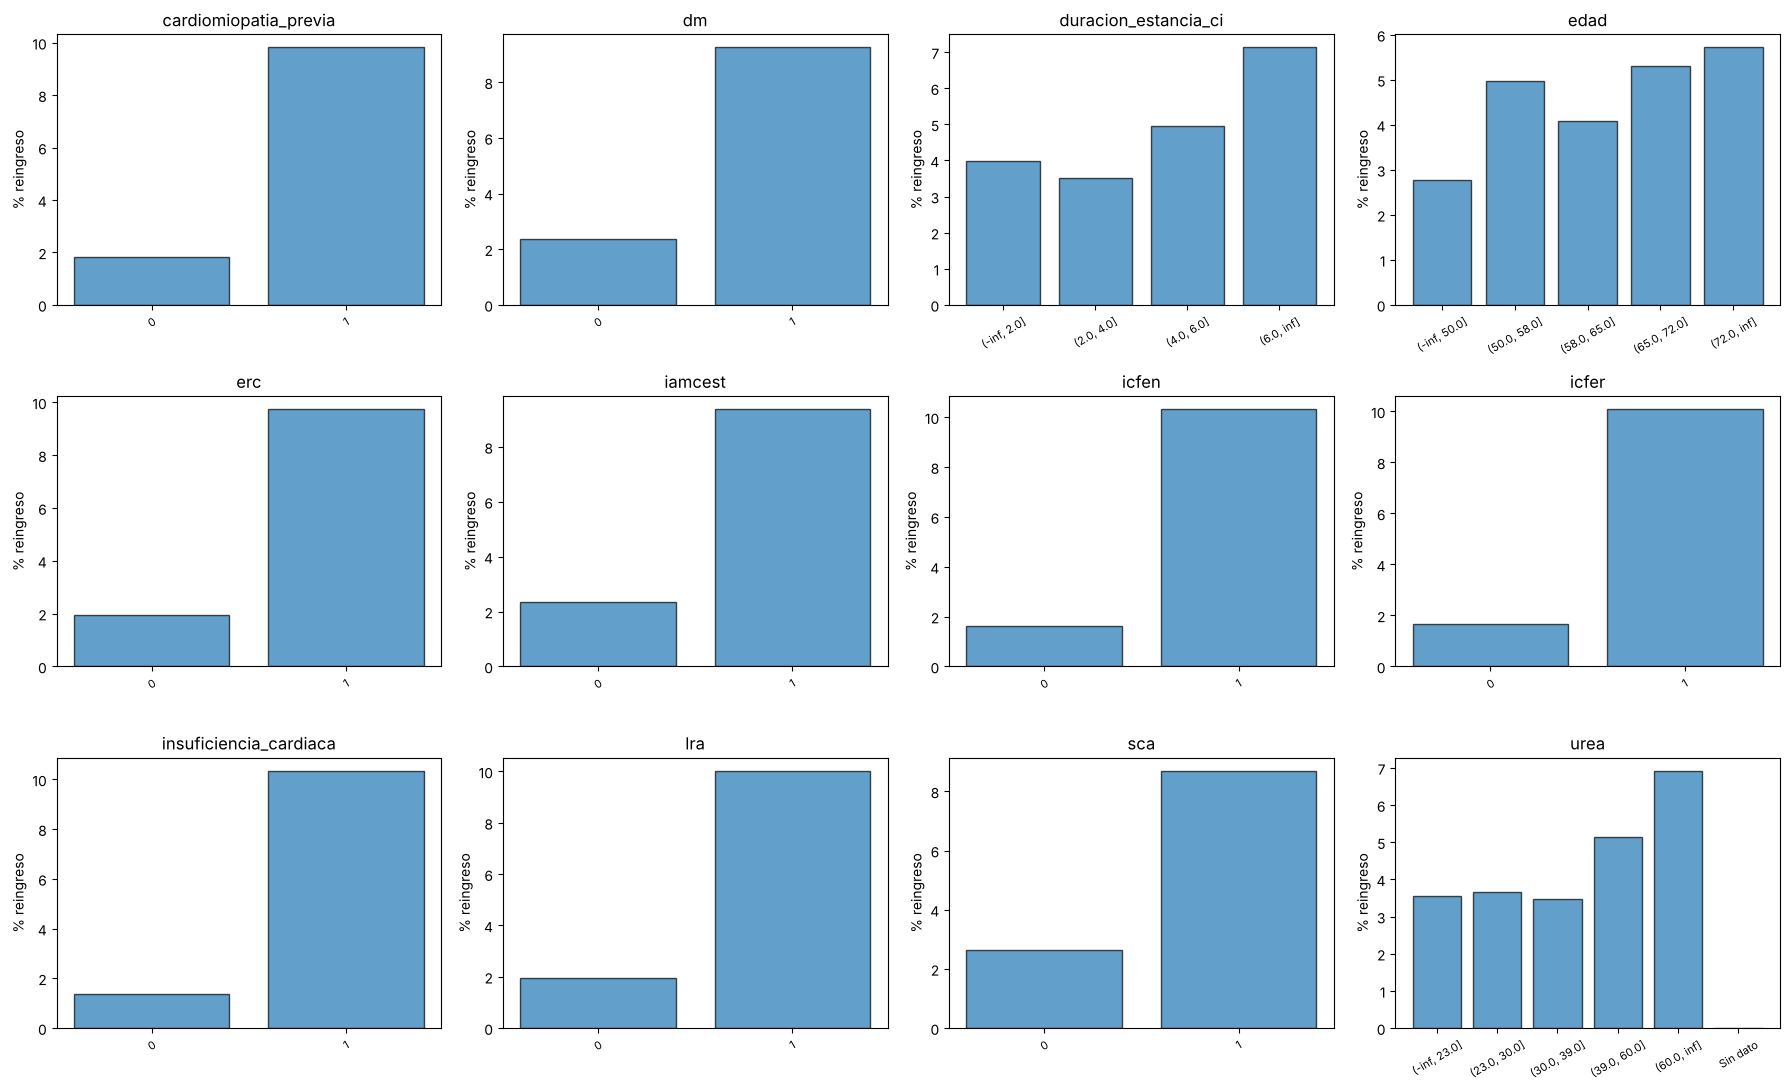

In [47]:
variables_minicubo = minicubo['variable'].unique()
fig, ejes = plt.subplots(3, 4, figsize=(18, 11))
for eje, variable in zip(ejes.flat, variables_minicubo):
    subset = minicubo[minicubo['variable'] == variable]
    eje.bar(subset['value'], subset['genera_reingreso'] * 100, edgecolor='k', alpha=0.7)
    eje.set_title(variable)
    eje.set_ylabel('% reingreso')
    eje.tick_params(axis='x', rotation=30, labelsize=8)
for eje in list(ejes.flat)[len(variables_minicubo):]:
    eje.axis('off')
plt.tight_layout()
plt.show()

**Mejora:** los 12 gráficos se dibujan en una cuadrícula, para compararlos de un vistazo.

En los 9 diagnósticos, tener el diagnóstico (1) multiplica por 4 o 5 el % de reingreso frente a no tenerlo (0). En las continuas, el riesgo crece en general con la urea, la edad y los días en CI, aunque no de forma perfectamente escalonada. En `urea`, la categoría "Sin dato" (las pocas admisiones sin ese análisis) no tiene ningún reingreso y vale 0 puntos.

### 7.3 Corrección (error 12): diagnósticos que se solapan

In [48]:
ic = ['insuficiencia_cardiaca', 'icfer', 'icfen']
print('Correlación entre los tres diagnósticos de insuficiencia cardiaca:')
print(desarrollo[ic].corr().round(2))
print('\nAdmisiones con IC que tienen también ICFEr o ICFEn:',
      f"{((desarrollo['insuficiencia_cardiaca'] == 1) & ((desarrollo['icfer'] == 1) | (desarrollo['icfen'] == 1))).mean() * 100:.1f} %")

Correlación entre los tres diagnósticos de insuficiencia cardiaca:
                        insuficiencia_cardiaca  icfer  icfen
insuficiencia_cardiaca                    1.00   0.29   0.28
icfer                                     0.29   1.00   0.27
icfen                                     0.28   0.27   1.00

Admisiones con IC que tienen también ICFEr o ICFEn: 24.0 %


El *scorecard* suma los puntos de cada variable como si fueran independientes. Clínicamente, la ICFEr y la ICFEn son los dos tipos de insuficiencia cardiaca, así que en datos reales estas tres columnas irían juntas, y un paciente con IC sumaría puntos **dos o tres veces por la misma enfermedad**.

En estos datos no pasa: la correlación entre ellas es de solo 0,28 y solo el 24 % de las admisiones con IC tiene también ICFEr o ICFEn. Se comportan como variables casi independientes, lo que vuelve a apuntar a datos sintéticos. El doble conteo aquí es pequeño.

Es una **limitación del método** que hay que tener presente: con datos reales, los modelos que tienen en cuenta la relación entre variables, como la regresión logística (la base de los scorecards de riesgo de crédito), reparten el peso entre ellas en lugar de sumarlo varias veces.

## 8. Risk Score Card (`03_Minicubo_y_RSC`)

### 8.1 Tabla de puntos

Los puntos de cada categoría son su penetración × 100, es decir, su % de reingreso.

**Corrección (error 8):** el original hacía `(penetración * 100).astype('int')`, y `astype('int')` **trunca** (8,88 pasa a 8). Aquí se redondea a 1 decimal.

In [49]:
rsc = minicubo.copy()
rsc['puntos'] = (rsc['genera_reingreso'] * 100).round(1)
rsc

,variable,value,admisiones,genera_reingreso,puntos
0,cardiomiopatia_previa,0,5177,0.018157,1.8
1,cardiomiopatia_previa,1,2616,0.098242,9.8
2,dm,0,5383,0.023779,2.4
3,dm,1,2410,0.092531,9.3
4,duracion_estancia_ci,"(-inf, 2.0]",3703,0.039698,4.0
5,duracion_estancia_ci,"(2.0, 4.0]",1704,0.035211,3.5
6,duracion_estancia_ci,"(4.0, 6.0]",1194,0.049414,4.9
7,duracion_estancia_ci,"(6.0, inf]",1192,0.071309,7.1
8,edad,"(-inf, 50.0]",1586,0.027743,2.8
9,edad,"(50.0, 58.0]",1547,0.049774,5.0


**Corrección (error 13):** en el original, la celda `rsc['puntos'] = ...` se había ejecutado cuando `minicubo` todavía era la tabla ancha (una fila por admisión). Por eso la salida guardada no es una tabla de puntos. Aquí `rsc` sale del minicubo ya agregado.

### 8.2 Función de scoring

**Corrección (errores 6 y 14).** El original pidió a la IA una función con reglas si-entonces escritas a mano (`if registro.get("dm") == 1: scoring += 49`...). Tenía tres problemas:

1. **Nunca sumaba los puntos de edad ni de las estancias**, porque preguntaba por las columnas `edad_disc`, `duracion_estancia_disc` y `duracion_estancia_ci_disc`, que no existían en `risk`. Prueba: el rango que salía, de 84 a 457, es exactamente la suma de los puntos mínimos y máximos de las 9 binarias (8+11+10+12+8+7+6+10+12 = 84 y 52+49+51+47+53+54+54+50+47 = 457).
2. Si cambian los datos, hay que reescribir la función a mano, y un número mal copiado no se detecta.
3. Aplicada fila a fila con `apply`, es lenta.

Aquí los puntos se buscan en la tabla `rsc`, y la propia función se encarga de discretizar las continuas con los cortes guardados:

In [50]:
# Diccionario {variable: {valor: puntos}} a partir de la tabla rsc
tabla_puntos = {variable: grupo.set_index('value')['puntos'].to_dict() for variable, grupo in rsc.groupby('variable')}

def calcular_scoring(datos, tabla_puntos, cortes):
    # Suma los puntos de cada variable del scorecard para todas las filas a la vez
    preparados = pd.DataFrame(index=datos.index)
    for variable in tabla_puntos:
        if variable in cortes:
            valores = tramificar(datos[variable], cortes[variable])
        else:
            valores = datos[variable].astype(str)
        # Una categoría que no estaba en desarrollo recibe los puntos más bajos de la variable
        preparados[variable] = valores.map(tabla_puntos[variable]).fillna(min(tabla_puntos[variable].values()))
    return preparados.sum(axis=1)

desarrollo['scoring_puntos'] = calcular_scoring(desarrollo, tabla_puntos, cortes)
prueba['scoring_puntos'] = calcular_scoring(prueba, tabla_puntos, cortes)

desarrollo.groupby('genera_reingreso')['scoring_puntos'].mean()

genera_reingreso
0    52.777466
1    81.941880
Name: scoring_puntos, dtype: float64

La función trabaja con **toda la tabla a la vez** (`.map` sobre columnas), sin recorrer fila a fila, y lee los puntos de la tabla en lugar de llevarlos copiados. Si mañana se recalcula el scorecard con datos nuevos, la función no cambia.

Los pacientes que reingresan tienen, de media, una puntuación claramente más alta.

### 8.3 Cambio de escala a 0-10

**Corrección (error 7).** El texto original decía "el mínimo y el máximo que se puede conseguir con nuestra tabla de puntuaciones", pero el código usaba `risk['scoring'].min()` y `.max()`, que son el mínimo y el máximo **de los pacientes de esa tabla**. En producción eso es un problema: cada ejecución tiene otros pacientes, otros mínimos y máximos, y el mismo paciente podría sacar un 6 un día y un 7 al siguiente.

El mínimo y el máximo **teóricos** salen de la tabla de puntos: el paciente con menos riesgo posible tiene el valor más bajo de cada variable, y el de más riesgo, el más alto. Son fijos.

In [51]:
PUNTOS_MIN = sum(min(puntos.values()) for puntos in tabla_puntos.values())
PUNTOS_MAX = sum(max(puntos.values()) for puntos in tabla_puntos.values())
print(f'Rango teórico de puntos: {PUNTOS_MIN:.1f} a {PUNTOS_MAX:.1f}')

def escalar_0_10(puntos):
    # Reescala los puntos a 0-10 con el rango teórico y redondea (el original truncaba con astype(int))
    return ((puntos - PUNTOS_MIN) / (PUNTOS_MAX - PUNTOS_MIN) * 10).round().clip(0, 10).astype(int)

desarrollo['scoring'] = escalar_0_10(desarrollo['scoring_puntos'])
prueba['scoring'] = escalar_0_10(prueba['scoring_puntos'])

desarrollo['scoring'].value_counts().sort_index()

Rango teórico de puntos: 24.1 a 107.4


scoring
0       92
1      970
2     1952
3     1701
4      878
5      498
6      467
7      606
8      450
9      158
10      21
Name: count, dtype: int64

`.clip(0, 10)` es una protección: no debería pasar, pero si una categoría nueva sacara de rango a algún paciente, se queda en 0 o en 10.

### 8.4 Guardar el scorecard

**Mejora.** El script de producción no debe recalcular el scorecard: debe **usar** el que se ha construido aquí. El original lo resolvía pegando la función con los números escritos a mano. Aquí se guarda todo lo necesario en un archivo JSON (puntos, cortes y rango) y producción lo lee.

Así hay una única fuente de verdad: si se recalcula el scorecard, se regenera el archivo y producción lo usa sin tocar su código.

In [52]:
RUTA_SCORECARD = Path('scorecard_reingresos.json')

scorecard = {
    'ventana_dias': VENTANA_DIAS,
    'fecha_corte_desarrollo': str(FECHA_CORTE.date()),
    'puntos': tabla_puntos,
    # JSON no admite infinito: se guardan solo los cortes intermedios
    'cortes': {variable: c[1:-1] for variable, c in cortes.items()},
    'puntos_min': PUNTOS_MIN,
    'puntos_max': PUNTOS_MAX,
}
RUTA_SCORECARD.write_text(json.dumps(scorecard, indent=2, ensure_ascii=False))
print(RUTA_SCORECARD.read_text())

{
  "ventana_dias": 30,
  "fecha_corte_desarrollo": "2023-07-01",
  "puntos": {
    "cardiomiopatia_previa": {
      "0": 1.8,
      "1": 9.8
    },
    "dm": {
      "0": 2.4,
      "1": 9.3
    },
    "duracion_estancia_ci": {
      "(-inf, 2.0]": 4.0,
      "(2.0, 4.0]": 3.5,
      "(4.0, 6.0]": 4.9,
      "(6.0, inf]": 7.1
    },
    "edad": {
      "(-inf, 50.0]": 2.8,
      "(50.0, 58.0]": 5.0,
      "(58.0, 65.0]": 4.1,
      "(65.0, 72.0]": 5.3,
      "(72.0, inf]": 5.7
    },
    "erc": {
      "0": 2.0,
      "1": 9.7
    },
    "iamcest": {
      "0": 2.3,
      "1": 9.4
    },
    "icfen": {
      "0": 1.6,
      "1": 10.3
    },
    "icfer": {
      "0": 1.7,
      "1": 10.1
    },
    "insuficiencia_cardiaca": {
      "0": 1.4,
      "1": 10.4
    },
    "lra": {
      "0": 2.0,
      "1": 10.0
    },
    "sca": {
      "0": 2.6,
      "1": 8.7
    },
    "urea": {
      "(-inf, 23.0]": 3.5,
      "(23.0, 30.0]": 3.7,
      "(30.0, 39.0]": 3.5,
      "(39.0, 60.0]": 5.1,


## 9. Validación (error 10)

**Mejora.** El original comprobaba que los que reingresaban tenían más puntos de media, pero con los mismos datos con los que se había construido el scorecard. Aquí se mide en el periodo de **prueba**, con pacientes que el scorecard no ha visto.

La medida estándar es el **AUC** (*Area Under the ROC Curve*): la probabilidad de que, cogiendo al azar un paciente que reingresa y otro que no, el que reingresa tenga más puntos.

| AUC | Lectura |
|---|---|
| 0,5 | Como tirar una moneda: el scorecard no sirve |
| 0,7-0,8 | Aceptable |
| 0,8-0,9 | Bueno |
| más de 0,9 | Excelente (y conviene sospechar si los datos son reales) |

In [53]:
auc_desarrollo = roc_auc_score(desarrollo['genera_reingreso'], desarrollo['scoring_puntos'])
auc_prueba = roc_auc_score(prueba['genera_reingreso'], prueba['scoring_puntos'])
print(f'AUC en desarrollo: {auc_desarrollo:.3f}')
print(f'AUC en prueba:     {auc_prueba:.3f}')

AUC en desarrollo: 0.892
AUC en prueba:     0.892


El AUC en prueba es prácticamente igual que en desarrollo: el scorecard **no está sobreajustado** y funciona igual de bien con pacientes nuevos. Un AUC cercano a 0,9 es muy alto para un modelo de reingresos (en estudios con datos reales se suele estar entre 0,65 y 0,75). Es otra señal de que los datos son sintéticos y la relación entre diagnósticos y reingreso es más limpia que en la realidad.

**¿Qué aportan las correcciones?** Se compara el scorecard original (con sus puntos y su error de edad y estancias) con el corregido, en el periodo de prueba y con el reingreso a 30 días:

In [54]:
# Puntos del scorecard original: solo las 9 binarias, como pasaba por el error 6
puntos_originales = {'cardiomiopatia_previa': (8, 52), 'dm': (11, 49), 'erc': (10, 51), 'iamcest': (12, 47),
                     'icfen': (8, 53), 'icfer': (7, 54), 'insuficiencia_cardiaca': (6, 54), 'lra': (10, 50), 'sca': (12, 47)}
scoring_original = sum(np.where(prueba[v] == 1, si, no) for v, (no, si) in puntos_originales.items())

print(f"AUC del scorecard original en prueba:  {roc_auc_score(prueba['genera_reingreso'], scoring_original):.3f}")
print(f"AUC del scorecard corregido en prueba: {auc_prueba:.3f}")

AUC del scorecard original en prueba:  0.891
AUC del scorecard corregido en prueba: 0.892


Los dos ordenan a los pacientes prácticamente igual de bien. Esto quiere decir que **el método del original funcionaba**: los 9 diagnósticos llevan casi toda la información, y por eso olvidar la edad y las estancias apenas se nota. Lo que cambia con las correcciones es:

1. **La fiabilidad de lo que se afirma.** El original no medía el rendimiento con datos nuevos; ahora sí se sabe que funciona.
2. **El significado de la nota.** El objetivo es el reingreso a 30 días, sin duplicados ni censura.
3. **La estabilidad en producción.** La escala es fija y la función usa todas las variables.

### 9.1 ¿La nota de 0 a 10 ordena el riesgo?

In [55]:
validacion = prueba.groupby('scoring').agg(admisiones=('genera_reingreso', 'size'),
                                           reingresos=('genera_reingreso', 'sum'),
                                           tasa_reingreso=('genera_reingreso', 'mean'))
validacion['tasa_reingreso_%'] = (validacion.pop('tasa_reingreso') * 100).round(1)
validacion

,admisiones,reingresos,tasa_reingreso_%
scoring,,,
0,43,0,0.0
1,554,0,0.0
2,1065,1,0.1
3,961,1,0.1
4,574,9,1.6
5,285,23,8.1
6,269,39,14.5
7,299,59,19.7
8,212,41,19.3


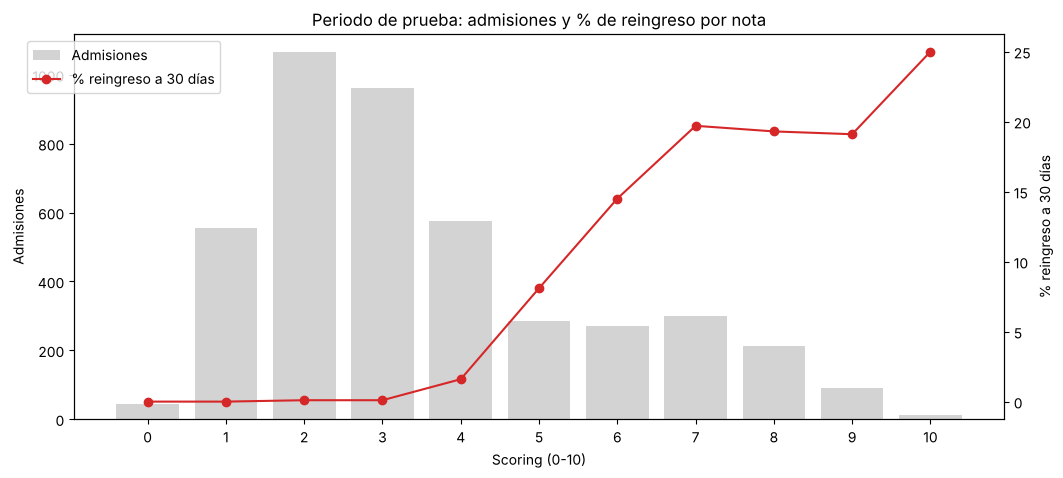

In [56]:
fig, eje1 = plt.subplots(figsize=(12, 5))
eje1.bar(validacion.index, validacion['admisiones'], color='lightgrey', label='Admisiones')
eje1.set_xlabel('Scoring (0-10)')
eje1.set_ylabel('Admisiones')
eje1.set_xticks(range(11))
eje2 = eje1.twinx()
eje2.plot(validacion.index, validacion['tasa_reingreso_%'], color='tab:red', marker='o', label='% reingreso a 30 días')
eje2.set_ylabel('% reingreso a 30 días')
eje1.set_title('Periodo de prueba: admisiones y % de reingreso por nota')
fig.legend(loc='upper left', bbox_to_anchor=(0.08, 0.88))
plt.show()

El gráfico del original (media de `genera_reingreso` por nota) se mantiene, ahora en el periodo de prueba y con el número de admisiones de cada nota.

Lectura:

- Con nota 3 o menos, el reingreso a 30 días es prácticamente nulo (2 de 2.623 altas); con 4, del 1,6 %.
- A partir de 5 sube con fuerza (8 % en el 5, 15 % en el 6) y se estabiliza en torno al 19-20 % del 7 al 9.
- Las notas más altas tienen pocos pacientes, así que su porcentaje es menos estable.

Uso práctico: un **umbral en 5** separa a los pacientes en los que concentrar el seguimiento al alta (llamada a los pocos días, cita temprana en consulta). Ese grupo es una cuarta parte de las altas y acumula casi todos los reingresos:

In [57]:
UMBRAL = 5
alto_riesgo = prueba['scoring'] >= UMBRAL
print(f'Altas con nota >= {UMBRAL}: {alto_riesgo.mean() * 100:.1f} % de las altas')
print(f"Reingresos que se producen en ese grupo: {prueba.loc[alto_riesgo, 'genera_reingreso'].sum() / prueba['genera_reingreso'].sum() * 100:.1f} %")

Altas con nota >= 5: 26.7 % de las altas
Reingresos que se producen en ese grupo: 94.3 %


## 10. Producción (`Produccion.ipynb`)

El script de producción se ejecuta con la frecuencia que se programe y:

1. Accede a las fuentes originales de datos.
2. Aplica toda la limpieza y las transformaciones necesarias.
3. Calcula el risk score de cada admisión.
4. Escribe en el datamart la información limpia y enriquecida.

Debe ser limpio (se exportará a un `.py`): sin gráficos, sin salidas de exploración y sin Markdown, solo comentarios con `#`. Y **no crea recursos, los usa**: el scorecard ya está construido y producción solo lo aplica.

**Correcciones respecto al `Produccion.ipynb` original:**

- La contraseña no está en el código (error 1).
- Se eliminan los episodios duplicados y se desempata el orden (errores 3 y 15).
- El scorecard se lee del archivo JSON, con todas sus variables (errores 6 y 14).
- La escala es fija (errores 7 y 8): la nota de un paciente no depende de los demás pacientes de la carga.
- Además de `reingreso` (¿es esta admisión un reingreso?), se escribe `reingreso_30d` (¿lo es dentro de los 30 días del alta anterior?), para que el dashboard pueda mostrar los dos indicadores.

Aquí se escribe como **una función**. Así se puede probar en el notebook y llamarla desde un `.py` programado.

In [58]:
def ejecutar_produccion(url_bd, ruta_scorecard, tabla_salida='tablon_scoring'):
    # Lee las tablas, limpia, calcula el scoring con el scorecard guardado y escribe el tablón
    motor = create_engine(url_bd)

    # Recurso ya creado: el scorecard (los cortes se guardaron sin los extremos infinitos)
    rsc_prod = json.loads(Path(ruta_scorecard).read_text())
    cortes_prod = {v: [-np.inf] + c + [np.inf] for v, c in rsc_prod['cortes'].items()}

    # Carga de los datos
    with motor.connect() as conexion:
        tablas = {nombre: pd.read_sql(f'SELECT * FROM {nombre}', conexion) for nombre in
                  ['admisiones', 'diagnosticos', 'factores_riesgo', 'pacientes', 'pruebas_laboratorio']}
    for columna in ['fecha_admision', 'fecha_alta']:
        tablas['admisiones'][columna] = pd.to_datetime(tablas['admisiones'][columna])

    # Integración
    datos = (tablas['pacientes']
             .merge(tablas['admisiones'].drop(columns=['id_paciente']), on='id_admision', how='left')
             .merge(tablas['factores_riesgo'], on=['id_admision', 'id_paciente'], how='left')
             .merge(tablas['pruebas_laboratorio'], on='id_admision', how='left')
             .merge(tablas['diagnosticos'], on='id_admision', how='left'))

    # Limpieza
    datos.loc[datos['duracion_estancia_ci'] > datos['duracion_estancia'], 'duracion_estancia_ci'] = datos['duracion_estancia']
    datos = datos.sort_values(['id_paciente', 'fecha_admision', 'id_admision'])
    datos = datos.drop_duplicates(['id_paciente', 'fecha_admision', 'fecha_alta'], keep='first')

    # Indicadores de reingreso (mirando hacia atrás: solo usan información disponible al ingresar)
    datos['reingreso'] = (datos['id_paciente'] == datos['id_paciente'].shift(1)).astype(int)
    dias_desde_alta_anterior = (datos['fecha_admision'] - datos.groupby('id_paciente')['fecha_alta'].shift(1)).dt.days
    datos['dias_desde_alta_anterior'] = dias_desde_alta_anterior
    datos['reingreso_30d'] = ((dias_desde_alta_anterior >= 0) & (dias_desde_alta_anterior <= 30)).astype(int)

    # Indicador histórico SOLO para el dashboard (mira hacia delante; el scoring no lo usa):
    # ¿esta alta acabó en un reingreso a 30 días? Permite mostrar la misma tasa que el análisis
    datos['dias_hasta_siguiente_ingreso'] = (datos.groupby('id_paciente')['fecha_admision'].shift(-1) - datos['fecha_alta']).dt.days
    datos['genera_reingreso_30d'] = datos['dias_hasta_siguiente_ingreso'].between(0, 30).astype(int)
    # Altas con 30 días de seguimiento: de las más recientes aún no se sabe si reingresarán
    datos['seguimiento_completo'] = (datos['fecha_alta'] <= datos['fecha_admision'].max() - pd.Timedelta(days=30)).astype(int)

    # Scoring con la tabla de puntos guardada y escala fija
    puntos = calcular_scoring(datos, rsc_prod['puntos'], cortes_prod)
    datos['scoring_puntos'] = puntos
    datos['scoring'] = (((puntos - rsc_prod['puntos_min']) / (rsc_prod['puntos_max'] - rsc_prod['puntos_min']) * 10)
                        .round().clip(0, 10).astype(int))

    # Escritura en el datamart
    datos.to_sql(tabla_salida, con=motor, if_exists='replace', index=False)
    motor.dispose()
    return datos

Diferencia entre las dos columnas de reingreso que escribe producción y la variable objetivo del modelo:

- `reingreso` y `reingreso_30d` miran **hacia atrás**: ¿esta admisión es un reingreso? Se pueden calcular en el momento en que el paciente ingresa. Son los indicadores del dashboard.
- `genera_reingreso` (el objetivo del modelo) mira **hacia delante**: ¿esta alta acabará en reingreso? Eso solo se sabe 30 días después. Por eso producción no lo calcula: es justo lo que el scoring intenta anticipar. Es la regla del enunciado de "no incluir información del futuro".
- `genera_reingreso_30d` es esa misma pregunta, pero sobre altas **ya pasadas**: se escribe solo para que el dashboard muestre la tasa de reingreso a 30 días del análisis (4,48 %), junto con `seguimiento_completo` para excluir las altas de los últimos 30 días. El scoring no usa ninguna de las dos, así que la regla de no usar información del futuro se sigue cumpliendo.

Se prueba la función. Escribe `tablon_scoring` en la base de datos a la que apunta `URL_BD`:

In [59]:
tablon = ejecutar_produccion(URL_BD, RUTA_SCORECARD)

print('Filas escritas:', len(tablon))
print(tablon[['id_admision', 'id_paciente', 'fecha_admision', 'reingreso', 'reingreso_30d', 'scoring_puntos', 'scoring']].head())

# Comprobación: la tasa del dashboard coincide con la del análisis
evaluables = tablon[(tablon['resultado'] != 'Defuncion') & (tablon['seguimiento_completo'] == 1)]
print(f"Tasa de reingreso a 30 días en el tablón: {evaluables['genera_reingreso_30d'].mean() * 100:.2f} % "
      f"({evaluables['genera_reingreso_30d'].sum()} de {len(evaluables)} altas)")

# Comprobaciones: producción da la misma nota que desarrollo para las mismas admisiones
comparar = prueba[['id_admision', 'scoring']].merge(tablon[['id_admision', 'scoring']], on='id_admision', suffixes=('_desarrollo', '_produccion'))
print('\nAdmisiones de prueba con nota distinta en producción:', (comparar['scoring_desarrollo'] != comparar['scoring_produccion']).sum())

with engine.connect() as conexion:
    print('Filas en tablon_scoring (releído de la base de datos):', pd.read_sql('SELECT COUNT(*) AS n FROM tablon_scoring', conexion)['n'].iloc[0])

Filas escritas: 13767
       id_admision  id_paciente fecha_admision  reingreso  reingreso_30d  scoring_puntos  scoring
14573        15196          506     2024-03-07          0              0            77.9        6
77              93          798     2022-04-05          0              0            78.0        6
3476          3526          798     2022-05-10          1              0            48.0        3
14521        15111          798     2024-03-04          1              0            39.2        2
12549        12720          989     2023-05-12          0              0            84.9        7
Tasa de reingreso a 30 días en el tablón: 4.48 % (544 de 12156 altas)

Admisiones de prueba con nota distinta en producción: 0
Filas en tablon_scoring (releído de la base de datos): 13767


Producción da exactamente la misma nota que el desarrollo para las mismas admisiones, y la tabla queda escrita en la base de datos.

Para programarlo, el `.py` solo tendría que hacer:

```python
import os
URL_BD = os.environ['URL_BD_CARDIOLOGIA']   # configurada en el servidor, nunca en el código
ejecutar_produccion(URL_BD, 'scorecard_reingresos.json')
```

**Corrección (error 17):** se elimina la celda `import sys; print(sys.executable)`, que mostraba la ruta del entorno de Anaconda con tu usuario de Windows.

## Resumen

### Lo que dicen los datos

| Pregunta | Respuesta |
|---|---|
| ¿Cuántos datos hay? | 15.038 admisiones de 11.796 pacientes (abril 2022 - marzo 2024), que son 13.767 episodios reales tras quitar duplicados |
| ¿Problemas de calidad? | 1.238 episodios duplicados, 24 pacientes con dos géneros, 90 ingresos solapados, 2 fallecidos que reingresan e incoherencias entre los diagnósticos de IC |
| ¿Cuántos reingresos? | 23,1 % con la definición original; **4,5 % a 30 días** sin duplicados ni censura |
| ¿Qué variables influyen? | 9 diagnósticos (IC, ICFEr, ICFEn, cardiomiopatía, LRA, ERC, IAMCEST, DM, SCA), muy por encima del resto, más urea, edad y días en CI |
| ¿Funciona el scorecard? | AUC ≈ 0,89 con pacientes que no ha visto. Con nota ≥ 5 están una cuarta parte de las altas y casi todos los reingresos |

### Glosario rápido

| Concepto | Qué es |
|---|---|
| Reingreso a 30 días | Nuevo ingreso del mismo paciente en los 30 días siguientes al alta |
| Censura por la derecha | Casos cuyo final aún no se conoce porque los datos terminan antes |
| Penetración | % de casos con el suceso (reingreso) dentro de una categoría |
| Chi-cuadrado | Prueba de si una variable categórica y el objetivo están relacionados |
| t de Welch | Prueba de si la media de una variable difiere entre dos grupos, sin suponer varianzas iguales |
| Minicubo | Tabla variable-valor-penetración a partir de la que se asignan los puntos |
| AUC | Probabilidad de que un caso positivo tenga más puntos que uno negativo (0,5 = azar, 1 = perfecto) |
| Desarrollo / prueba | Datos para construir el modelo / datos reservados para comprobar que funciona |
| `groupby().shift()` | Desplaza una columna dentro de cada grupo (fila anterior o siguiente del mismo paciente) |
| `melt` | Pasa una tabla de formato ancho a largo |